# Projeto 8: duração e acúmulo de processos na Justiça do Trabalho

**Introdução à Ciência de Dados · UFAL** · tema: *Política, saúde e acesso à justiça*

> **Pergunta central:** como variam a duração e o acúmulo de processos na Justiça do Trabalho?
>
> **Recorte:** a 1ª instância (as Varas do Trabalho) dos **24 Tribunais Regionais do Trabalho (TRTs)**, na **fase de conhecimento**, que vai da entrada do processo até a sentença ou o acordo. Medimos a **duração** dos processos encerrados em 2025 e o **estoque** de processos pendentes em 31/12/2025.

| | Pergunta |
|---|---|
| **P1** | Como se distribuem a duração e o estoque pendente nos 24 TRTs? |
| **P2** | Quanto da variação na duração se deve ao **tribunal** e quanto ao **perfil dos processos**? |
| **P3** | Quais fatores estão mais associados à longa duração e ao acúmulo? |

**Roteiro:** 1. Fontes · 2. Dados oficiais do CNJ · 3. Amostra de processos (DataJud) · 4. P1 · 5. P2 · 6. P3 · 7. Exercício: gráfico enganoso · 8. Ética · 9. Modelo de *machine learning* sugerido · **10. Relatório de resultados**

### Glossário
| Termo | O que significa |
|---|---|
| **TRT** | Tribunal Regional do Trabalho. São 24, cada um cobre uma região (em geral, um estado). São Paulo tem dois: TRT2 (capital, Grande SP e Baixada Santista) e TRT15 (interior). **O TRT19 é o de Alagoas.** |
| **Vara do Trabalho** | onde o processo começa (1ª instância), com um juiz |
| **Fase de conhecimento** | a parte do processo em que o juiz decide quem tem razão. Vai da entrada (ajuizamento) até a sentença. Depois, se a empresa não paga, começa a fase de execução (a cobrança), que não entra aqui |
| **Sentença / acordo** | a decisão do juiz. Quando as partes fazem um acordo, o juiz o homologa (aprova), e isso também encerra a fase |
| **Estoque (pendentes)** | processos que ainda esperavam sentença em 31/12/2025 |
| **Taxa de congestionamento** | % dos processos que passaram pelo tribunal no ano e terminaram o ano sem solução |
| **Rito** | o "trilho" do processo. **Sumaríssimo:** causas de até 40 salários mínimos, que a lei manda andar mais rápido. **Ordinário:** as demais |
| **Juízo 100% Digital** | opção em que tudo, inclusive as audiências, é feito pela internet |

### Como rodar
[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/joaolevi/projeto8-justica-do-trabalho/blob/main/projeto8_tramitacao_congestionamento.ipynb)

No Colab, use *Executar tudo*: a célula abaixo clona o repositório com os dados. No computador, basta abrir o notebook na pasta do repositório.

In [1]:
import os
import subprocess
import sys

REPOSITORIO = "https://github.com/joaolevi/projeto8-justica-do-trabalho.git"
if "google.colab" in sys.modules and not os.path.isdir("dados/brutos"):
    if not os.path.isdir("projeto8-justica-do-trabalho"):
        subprocess.run(["git", "clone", "--depth", "1", "-q", REPOSITORIO], check=True)
    os.chdir("projeto8-justica-do-trabalho")
print("Dados do projeto encontrados:", "sim" if os.path.isdir("dados/brutos") else "NÃO (abra o notebook na pasta do projeto)")

Dados do projeto encontrados: sim


## 1. Fontes: o que usamos e por quê

| Fonte | O que tem | Usamos? | Por quê |
|---|---|---|---|
| **Base do Justiça em Números 2026** (CNJ) | um número por TRT por ano: estoque, duração média, sentenças, juízes | **Sim** | é o dado oficial, o mesmo do relatório do CNJ. Responde à P1 e à parte da P3 sobre tribunais |
| **API Pública do DataJud** (CNJ) | dados de **cada processo**: datas, rito, assuntos, vara, movimentações | **Sim, por amostra** | só olhando processo a processo dá para separar tribunal de perfil (P2) e ver a variação dentro de cada TRT |
| Painel de Estatísticas do CNJ | os mesmos indicadores, num painel interativo | Não | o download de dados abertos responde "403 – Request blocked" (testado em 23/11/2026, com e sem navegador). O problema é do servidor do CNJ. Os números por TRT são os mesmos da base acima |
| Estatísticas do TST | relatórios com totais por TRT | Não | só têm totais por tribunal, sem dados por processo. Não ajudam na P2 |

**Decisões de escopo (ajustes à proposta do grupo):**
- **"Encerrado em 2025" = primeira sentença em 2025, contando o acordo homologado.** *Por quê:* é exatamente a definição do indicador oficial do CNJ, o que nos permite conferir nossos números com os dele. Não usamos a "baixa" porque, na Justiça do Trabalho, depois da sentença o processo costuma continuar na execução.
- **O estoque é medido de duas formas: tamanho e idade.** *Por quê:* a duração dos encerrados só enxerga quem já terminou (o chamado viés de sobrevivência). A idade do estoque mostra quem ficou para trás.
- **"Perfil do processo" = o que a API pública mostra:** rito, quantidade e tema dos assuntos. (O Juízo 100% Digital ficou de fora: o registro dele não é confiável, como mostra a seção 3.1.) *Limitação:* o valor da causa e o tipo de empresa não estão disponíveis.

## 2. Dados oficiais do CNJ (um número por TRT)
A base do *Justiça em Números* traz, para cada tribunal e cada ano, os totais e as médias que o CNJ publica no relatório anual. Dela vêm o estoque, a duração média e os demais indicadores por TRT.

In [2]:
import gzip
import json
import re
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from scipy import stats

ANO = 2025
DESTAQUE = "TRT19"
MES = 30.44
TRTS = [f"TRT{i}" for i in range(1, 25)]

URL_BASE = "https://www.cnj.jus.br/wp-content/uploads/2026/09/17-set-2026.zip"

DIR_BRUTOS, DIR_TRATADOS, DIR_FIG = Path("dados/brutos"), Path("dados/tratados"), Path("figuras")
for pasta in (DIR_BRUTOS, DIR_TRATADOS, DIR_FIG):
    pasta.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 1)

COR = {"fundo": "#fcfcfb", "tinta": "#0b0b0b", "tinta2": "#52514e", "mudo": "#898781",
       "grade": "#e1e0d9", "eixo": "#c3c2b7", "contexto": "#bdbcb4",
       "azul": "#2a78d6", "laranja": "#eb6834", "verde": "#1baf7a", "vermelho": "#c62828"}
plt.rcParams.update({
    "figure.facecolor": COR["fundo"], "axes.facecolor": COR["fundo"], "savefig.facecolor": COR["fundo"],
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10.5,
    "text.color": COR["tinta"], "axes.edgecolor": COR["eixo"], "axes.labelcolor": COR["tinta2"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": COR["grade"], "xtick.color": COR["eixo"], "ytick.color": COR["eixo"],
    "xtick.labelcolor": COR["tinta2"], "ytick.labelcolor": COR["tinta2"], "legend.frameon": False,
})


def num(v, casas=0):
    return f"{v:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")


def pct(v, casas=1):
    return num(v, casas) + "%"


def titulo(ax, texto, subtitulo=None):
    ax.set_title(texto, loc="left", fontsize=13, fontweight="bold", pad=24 if subtitulo else 10)
    if subtitulo:
        ax.text(0, 1.012, subtitulo, transform=ax.transAxes, fontsize=10, color=COR["tinta2"], va="bottom")


def rotulos_trt(ax, siglas):
    ax.set_yticks(np.arange(len(siglas)), [ROTULO[s] for s in siglas])
    for rotulo, s in zip(ax.get_yticklabels(), siglas):
        if s == DESTAQUE:
            rotulo.set_fontweight("bold")
            rotulo.set_color(COR["tinta"])
    ax.set_ylim(-0.7, len(siglas) - 0.3)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)


def salvar(fig, nome):
    fig.savefig(DIR_FIG / f"{nome}.png")

In [3]:
arq_zip = DIR_BRUTOS / "jn2026_base_17-set-2026.zip"
if not arq_zip.exists():
    pedido = urllib.request.Request(URL_BASE, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(pedido, timeout=120) as resposta:
        arq_zip.write_bytes(resposta.read())

with zipfile.ZipFile(arq_zip) as zf:
    print("Arquivos dentro do zip:", zf.namelist())
    nome = next(n for n in zf.namelist() if n.startswith("JN_"))
    with zf.open(nome) as f:
        base = pd.read_csv(f, sep=";", encoding="cp1252", decimal=",", na_values=["nd"], low_memory=False)
print(f"Base completa: {num(base.shape[0])} linhas (1 linha = 1 tribunal em 1 ano) e {num(base.shape[1])} colunas")

Arquivos dentro do zip: ['Variáveis - JN.csv', 'BD_Consolidado_JF_Secao_23_Jun_2026.csv', 'JN_23-Jun-2026.csv']


Base completa: 1.595 linhas (1 linha = 1 tribunal em 1 ano) e 1.314 colunas


### 2.2 Limpeza: o que encontramos e o que decidimos
| Passo | O que encontramos | O que fizemos | Por quê |
|---|---|---|---|
| 1 | A base tem **todos** os ramos da Justiça (estadual, federal, eleitoral...) | ficamos só com a Justiça do Trabalho | é o recorte do grupo |
| 2 | Uma linha com sigla "TRT" que **não é um tribunal**: é a soma dos 24 | separamos como referência | se ficasse junto, viraria um "25º TRT" gigante e dobraria os totais |
| 3 | 1.314 colunas com nomes em código (`tpsentc1m`, `cpc1`...) | ficamos com 17 colunas e demos nomes em português | menos colunas, menos chance de erro, e qualquer pessoa entende os nomes |
| 4 | Taxas guardadas como fração (0,35) | convertemos para % (35%) | é como o relatório oficial publica, o que facilita conferir |
| 5 | Estoques de tamanhos muito diferentes (6 mil a 300 mil processos) | criamos medidas relativas, como "meses para zerar o estoque" | só assim dá para comparar um TRT pequeno com um grande |
| 6 | Indicadores que já vêm calculados | recalculamos a partir das contagens e comparamos | se baterem, entendemos certo o que cada coluna mede |
| 7 | Valores que parecem estranhos | **não apagamos nada automaticamente**: usamos uma regra de alerta e decidimos caso a caso | um valor extremo pode ser real (um mutirão, por exemplo). Apagá-lo esconderia justamente o que é interessante |

In [4]:
trab = base[base["justica"] == "Trabalho"]

total_bruto = trab[trab["sigla"] == "TRT"]
trts_bruto = trab[trab["sigla"] != "TRT"]
soma = trts_bruto.groupby("ano")[["cnc1", "cpc1", "tbaixc1"]].sum()
print("Diferença entre a soma dos 24 TRTs e a linha 'TRT':",
      (soma - total_bruto.set_index("ano")[["cnc1", "cpc1", "tbaixc1"]]).abs().max().max())

print("Quantidade de TRTs em cada ano:", sorted(trts_bruto.groupby("ano")["sigla"].nunique().unique()))
print("Tribunal repetido no mesmo ano:", int(trts_bruto.duplicated(["ano", "sigla"]).sum()))

Diferença entre a soma dos 24 TRTs e a linha 'TRT': 0.0
Quantidade de TRTs em cada ano: [np.int64(24)]
Tribunal repetido no mesmo ano: 0


In [5]:
VARIAVEIS = {
    "ano": ("ano", "ano-base"),
    "sigla": ("sigla", "sigla do tribunal"),
    "uf_sede": ("uf", "estado da sede do TRT"),
    "porte": ("porte", "porte do TRT segundo o CNJ (Grande, Médio ou Pequeno)"),
    "cnc1": ("casos_novos", "processos que entraram no ano"),
    "cpc1": ("pendentes", "ESTOQUE: processos sem sentença em 31/12"),
    "susc1": ("suspensos", "parte do estoque parada por motivo legal (ex.: à espera de um tribunal superior)"),
    "tbaixc1": ("baixados", "processos que saíram da fase de conhecimento no ano"),
    "sentc1": ("sentencas", "sentenças no ano (inclui as que homologam acordo)"),
    "senthc1": ("acordos", "sentenças que homologam acordo"),
    "tpsentc1p": ("n_processos_duracao", "quantos processos entram na média de duração"),
    "tpsentc1m": ("dias_ate_sentenca", "DURAÇÃO: média de dias da entrada até a 1ª sentença, para quem foi sentenciado no ano"),
    "tpcpc1m": ("dias_idade_estoque", "IDADE DO ESTOQUE: média de dias da entrada até 31/12, para os pendentes"),
    "tcc1": ("tc", "taxa de congestionamento (%) = pendentes ÷ (pendentes + baixados)"),
    "icc1": ("indice_conciliacao", "% das sentenças que foram acordos"),
    "mag1": ("juizes", "cargos de juiz no 1º grau"),
    "sajudmag1": ("servidores_por_juiz", "servidores da área judiciária por juiz, no 1º grau"),
}
DERIVADAS = {
    "meses_ate_sentenca": "dias_ate_sentenca ÷ 30,44",
    "meses_idade_estoque": "dias_idade_estoque ÷ 30,44",
    "meses_para_zerar_estoque": "12 × pendentes ÷ baixados: meses para zerar o estoque no ritmo de saída de 2025",
    "casos_novos_por_juiz": "casos_novos ÷ juizes",
    "pct_suspensos": "100 × suspensos ÷ pendentes",
}


def preparar(tabela):
    t = tabela[list(VARIAVEIS)].rename(columns={s: v[0] for s, v in VARIAVEIS.items()})
    t[["tc", "indice_conciliacao"]] *= 100
    t["meses_ate_sentenca"] = t["dias_ate_sentenca"] / MES
    t["meses_idade_estoque"] = t["dias_idade_estoque"] / MES
    t["meses_para_zerar_estoque"] = 12 * t["pendentes"] / t["baixados"]
    t["casos_novos_por_juiz"] = t["casos_novos"] / t["juizes"]
    t["pct_suspensos"] = 100 * t["suspensos"] / t["pendentes"]
    return t


hist = preparar(trts_bruto).reset_index(drop=True)
total = preparar(total_bruto).set_index("ano").loc[ANO]
jt = hist[hist["ano"] == ANO].set_index("sigla").loc[TRTS]
ROTULO = {s: f"{s} · {uf}" for s, uf in jt["uf"].items()}

dif_tc = (100 * jt["pendentes"] / (jt["pendentes"] + jt["baixados"]) - jt["tc"]).abs().max()
dif_icc = (100 * jt["acordos"] / jt["sentencas"] - jt["indice_conciliacao"]).abs().max()
print(f"Maior diferença entre o recalculado e o do CNJ: taxa de congestionamento {num(dif_tc, 2)} | "
      f"índice de conciliação {num(dif_icc, 2)} (em pontos percentuais)")
print("Valores vazios nos 24 TRTs em 2025:", int(jt.isna().sum().sum()))

Maior diferença entre o recalculado e o do CNJ: taxa de congestionamento 0,00 | índice de conciliação 0,00 (em pontos percentuais)
Valores vazios nos 24 TRTs em 2025: 0


In [6]:
h = hist[hist["ano"].between(2016, ANO)]
ALERTAS = {}
for col in ["dias_ate_sentenca", "dias_idade_estoque", "pendentes"]:
    razao = h[col] / h.groupby("sigla")[col].transform("median")
    ALERTAS[col] = list(h[(h["ano"] == ANO) & ((razao < 1 / 3) | (razao > 3))]["sigla"])
    print(f"{col}: {', '.join(ALERTAS[col]) or 'nenhum alerta'}")

dias_ate_sentenca: nenhum alerta
dias_idade_estoque: TRT19
pendentes: nenhum alerta


In [7]:
display(hist.query("sigla == @DESTAQUE and ano >= 2020").set_index("ano")
        [["casos_novos", "baixados", "pendentes", "meses_idade_estoque"]].round(1).T)

ano,2020,2021,2022,2023,2024,2025
casos_novos,13225.0,16369.0,15960.0,18913.0,18267.0,21717.0
baixados,15827.0,16504.0,18774.0,28516.0,19877.0,20314.0
pendentes,23694.0,23320.0,20635.0,10250.0,7920.0,8930.0
meses_idade_estoque,20.0,21.1,22.5,9.0,7.0,5.3


**Decisão: manter.** Em 2023, o TRT19 baixou 28,5 mil processos e recebeu 18,9 mil. O estoque caiu de 20,6 mil para 10,3 mil, e os processos que saíram eram os mais antigos. A queda da idade do estoque é real.

In [8]:
opcoes = dict(sep=";", decimal=",", encoding="utf-8-sig")
jt.to_csv(DIR_TRATADOS / f"jn_trt_{ANO}.csv", **opcoes)
dicionario = pd.DataFrame(
    [{"coluna": n, "origem": f"CNJ ({s})", "o que é": d} for s, (n, d) in VARIAVEIS.items()]
    + [{"coluna": n, "origem": "calculada", "o que é": d} for n, d in DERIVADAS.items()])
dicionario.to_csv(DIR_TRATADOS / "dicionario_jn_trt.csv", index=False, **opcoes)
with pd.option_context("display.max_colwidth", 120):
    display(dicionario.set_index("coluna"))

,origem,o que é
coluna,,
ano,CNJ (ano),ano-base
sigla,CNJ (sigla),sigla do tribunal
uf,CNJ (uf_sede),estado da sede do TRT
porte,CNJ (porte),"porte do TRT segundo o CNJ (Grande, Médio ou Pequeno)"
casos_novos,CNJ (cnc1),processos que entraram no ano
pendentes,CNJ (cpc1),ESTOQUE: processos sem sentença em 31/12
suspensos,CNJ (susc1),parte do estoque parada por motivo legal (ex.: à espera de um tribunal superior)
baixados,CNJ (tbaixc1),processos que saíram da fase de conhecimento no ano
sentencas,CNJ (sentc1),sentenças no ano (inclui as que homologam acordo)


## 3. Amostra de processos (API Pública do DataJud)
A base oficial só tem a média de cada TRT. Para medir a variação dentro dos TRTs (P1) e separar tribunal de perfil (P2), precisamos de dados por processo, que só a API do DataJud oferece. É a mesma base que o CNJ usa no *Justiça em Números*.

| Decisão | Por quê |
|---|---|
| Amostra aleatória de pelo menos 500 processos encerrados por TRT | foram cerca de 2,2 milhões de sentenças em 2025; baixar tudo pela API levaria semanas |
| Mesmo tamanho de amostra em todos os TRTs | os TRTs pequenos também precisam de n suficiente |
| Peso = sentenças do TRT em 2025 ÷ processos dele na amostra | para que as estatísticas agregadas representem todos os TRTs |
| Só processos ajuizados a partir de 2015 | ver passo E da limpeza |
| Sorteio com `random_score` e semente fixa (2025) | reprodutibilidade |
| Nos TRTs grandes, sorteio por fatias de data de ajuizamento, com cota proporcional ao tamanho de cada fatia | a consulta inteira passa do limite de 60 s da API |
| Respostas guardadas em `dados/brutos/datajud/`; com `BAIXAR = False`, o notebook usa só esse cache | a coleta completa leva horas |
| Só entram TRTs com a amostra completa | uma amostra parcial ficaria enviesada, só com processos antigos |

In [9]:
import gzip, json, math, random, time, urllib.error, urllib.request
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

DATAJUD_URL = "https://api-publica.datajud.cnj.jus.br/api_publica_{trt}/_search"
DATAJUD_CHAVE = "cDZHYzlZa0JadVREZDJCendQbXY6SkJlTzNjLV9TRENyQk1RdnFKZGRQdw=="

CLASSES_CONHECIMENTO = {985: "Ordinário", 1125: "Sumaríssimo", 1126: "Sumário (alçada)"}

SENTENCA_ACORDO = {466}
SENTENCA_MERITO = {219, 220, 221, 455, 471, 11795}
SENTENCA_SEM_MERITO = {472, 473, 454, 457, 458, 459, 460, 461, 462, 463, 464, 12256}
CODIGOS_SENTENCA = SENTENCA_ACORDO | SENTENCA_MERITO | SENTENCA_SEM_MERITO

CAMPOS = ["dataAjuizamento", "classe.codigo", "classe.nome", "assuntos.codigo",
          "assuntos.nome", "orgaoJulgador.codigo", "orgaoJulgador.nome",
          "orgaoJulgador.codigoMunicipioIBGE", "movimentos.codigo",
          "movimentos.dataHora", "nivelSigilo"]

AJUIZ_INICIO, AJUIZ_FIM = "20150101000000", "20260101000000"
FATIAS = ["20150101000000", "20210101000000", "20230101000000", "20240101000000",
          "20240701000000", "20250101000000", "20250701000000", "20260101000000"]


def filtro_base(ini=AJUIZ_INICIO, fim=AJUIZ_FIM):
    return {"bool": {"filter": [
        {"match": {"grau": "G1"}},
        {"terms": {"classe.codigo": sorted(CLASSES_CONHECIMENTO)}},
        {"terms": {"movimentos.codigo": sorted(CODIGOS_SENTENCA)}},
        {"range": {"movimentos.dataHora": {"gte": "2025-01-01T00:00:00.000Z",
                                           "lt": "2026-01-01T00:00:00.000Z"}}},
        {"range": {"dataAjuizamento": {"gte": ini, "lt": fim}}},
    ]}}


def consulta_amostra(pagina, tamanho=1000, semente=2025, ini=AJUIZ_INICIO, fim=AJUIZ_FIM):
    return {"size": tamanho, "from": pagina * 1000, "_source": CAMPOS,
            "query": {"function_score": {"query": filtro_base(ini, fim),
                                         "random_score": {"seed": semente, "field": "_seq_no"},
                                         "boost_mode": "replace"}}}


class ConsultaPesada(Exception):
    pass


class ForaDoCache(Exception):
    pass


SO_CACHE = False


def post_com_espera(url, corpo, tentativas=3000, max_504=6):
    if SO_CACHE:
        raise ForaDoCache(url)
    dados = json.dumps(corpo).encode()
    n_504 = 0
    for _ in range(tentativas):
        req = urllib.request.Request(url, data=dados, method="POST", headers={
            "Authorization": f"APIKey {DATAJUD_CHAVE}", "Content-Type": "application/json",
            "User-Agent": "projeto-academico-ciencia-de-dados"})
        try:
            with urllib.request.urlopen(req, timeout=120) as r:
                resp = json.loads(r.read())
            if resp.get("_shards", {}).get("failed", 0) == 0 and not resp.get("timed_out"):
                return resp
        except urllib.error.HTTPError as e:
            if e.code == 504:
                n_504 += 1
                if n_504 >= max_504:
                    raise ConsultaPesada(url)
            elif e.code not in (429, 500, 502, 503):
                raise
        except (urllib.error.URLError, TimeoutError, ConnectionError):
            pass
        time.sleep(random.uniform(5, 15))
    raise RuntimeError(f"API não respondeu após {tentativas} tentativas: {url}")


def primeira_sentenca(movimentos):
    s = [(m["dataHora"], m["codigo"]) for m in movimentos or []
         if m.get("codigo") in CODIGOS_SENTENCA and m.get("dataHora")]
    return min(s) if s else (None, None)


def _baixa_pagina(arq, url, corpo):
    if not arq.exists():
        hits = post_com_espera(url, corpo)["hits"]["hits"]
        with gzip.open(arq, "wt", encoding="utf-8") as f:
            json.dump(hits, f, ensure_ascii=False)
        print(f"  {arq.name} baixado ({len(hits)} processos)", flush=True)
    with gzip.open(arq, "rt", encoding="utf-8") as f:
        return json.load(f)


def _validos(hits, vistos):
    n = 0
    for h in hits:
        if h["_id"] not in vistos:
            vistos.add(h["_id"])
            data, _ = primeira_sentenca(h["_source"].get("movimentos"))
            n += bool(data and data.startswith("2025"))
    return n


def coletar_trt(trt, pasta, alvo=500, max_paginas=5, docs_fatiado=2400):
    pasta.mkdir(parents=True, exist_ok=True)
    url = DATAJUD_URL.format(trt=trt.lower())
    arq_contagem = pasta / f"{trt.lower()}_fatias.json"
    if not arq_contagem.exists():
        validos, vistos = 0, set()
        try:
            for p in range(max_paginas):
                hits = _baixa_pagina(pasta / f"{trt.lower()}_p{p}.json.gz", url, consulta_amostra(p))
                validos += _validos(hits, vistos)
                if validos >= alvo or len(hits) < 1000:
                    return trt, validos, len(vistos), "simples"
            return trt, validos, len(vistos), "simples"
        except ConsultaPesada:
            for arq in pasta.glob(f"{trt.lower()}_p*.json.gz"):
                arq.unlink()
            print(f"  {trt}: consulta inteira passa de 60 s; usando fatias de ajuizamento", flush=True)
    if arq_contagem.exists():
        contagens = json.loads(arq_contagem.read_text())
    else:
        contagens = []
        for ini, fim in zip(FATIAS[:-1], FATIAS[1:]):
            contagens += _conta_fatia(url, ini, fim)
        arq_contagem.write_text(json.dumps(contagens))
    total = sum(c["n"] for c in contagens)
    validos, vistos = 0, set()
    fila = list(contagens)
    while fila:
        c = fila.pop(0)
        quota = math.ceil(docs_fatiado * c["n"] / total)
        nome = f"{trt.lower()}_f{c['ini'][:8]}_{c['fim'][:8]}"
        try:
            paginas = [_baixa_pagina(pasta / f"{nome}_p{p}.json.gz", url,
                                     consulta_amostra(p, tamanho=min(1000, quota - 1000 * p),
                                                      ini=c["ini"], fim=c["fim"]))
                       for p in range(math.ceil(quota / 1000))]
        except ConsultaPesada:
            for arq in pasta.glob(f"{nome}_p*.json.gz"):
                arq.unlink()
            meio = _meio(c["ini"], c["fim"])
            metades = _conta_fatia(url, c["ini"], meio) + _conta_fatia(url, meio, c["fim"])
            i = contagens.index(c)
            contagens[i:i + 1] = metades
            arq_contagem.write_text(json.dumps(contagens))
            fila[:0] = metades
            continue
        for hits in paginas:
            validos += _validos(hits, vistos)
    return trt, validos, len(vistos), "fatiado"


def _meio(ini, fim):
    a, b = (datetime.strptime(x, "%Y%m%d%H%M%S") for x in (ini, fim))
    return (a + (b - a) / 2).strftime("%Y%m%d") + "000000"


def _conta_fatia(url, ini, fim, dias_min=15):
    try:
        r = post_com_espera(url, {"size": 0, "track_total_hits": True, "query": filtro_base(ini, fim)})
        return [{"ini": ini, "fim": fim, "n": r["hits"]["total"]["value"]}]
    except ConsultaPesada:
        meio = _meio(ini, fim)
        if (datetime.strptime(fim, "%Y%m%d%H%M%S") - datetime.strptime(ini, "%Y%m%d%H%M%S")).days < 2 * dias_min:
            raise
        print(f"  {url.split('api_publica_')[1].split('/')[0].upper()}: fatia {ini[:8]}–{fim[:8]} pesada; "
              f"dividindo em {meio[:8]}", flush=True)
        return _conta_fatia(url, ini, meio) + _conta_fatia(url, meio, fim)


def coletar_todos(pasta, trts, alvo=500, paralelo=2, baixar=True):
    global SO_CACHE
    SO_CACHE = not baixar

    def seguro(trt):
        try:
            return coletar_trt(trt, pasta, alvo)
        except ForaDoCache:
            return trt, 0, 0, "INCOMPLETO no cache (fica fora da amostra)"
        except Exception as e:
            return trt, 0, 0, f"FALHOU: {type(e).__name__} (rode de novo para tentar só o que falta)"

    completos = []
    with ThreadPoolExecutor(max_workers=paralelo) as ex:
        for trt, validos, vistos, modo in ex.map(seguro, trts):
            print(f"{trt:>6}: {validos:>5} processos com 1ª sentença em 2025 "
                  f"(de {vistos} baixados; modo {modo})", flush=True)
            if modo in ("simples", "fatiado"):
                completos.append(trt)
    SO_CACHE = False
    return completos

In [10]:
BAIXAR = False
DIR_DATAJUD = DIR_BRUTOS / "datajud"
TRTS_AMOSTRA = coletar_todos(DIR_DATAJUD, TRTS, alvo=500, baixar=BAIXAR)
assert TRTS_AMOSTRA, "Nenhum TRT no cache: copie a pasta dados/brutos/datajud do Drive ou use BAIXAR = True"
print(f"\nTRTs com amostra completa: {len(TRTS_AMOSTRA)} de {len(TRTS)}. "
      f"Fora da amostra: {', '.join(sorted(set(TRTS) - set(TRTS_AMOSTRA), key=TRTS.index)) or 'nenhum'}")

  TRT1:   532 processos com 1ª sentença em 2025 (de 2000 baixados; modo simples)


  TRT2:     0 processos com 1ª sentença em 2025 (de 0 baixados; modo INCOMPLETO no cache (fica fora da amostra))


  TRT3:  1128 processos com 1ª sentença em 2025 (de 2404 baixados; modo fatiado)


  TRT4:   776 processos com 1ª sentença em 2025 (de 2405 baixados; modo fatiado)


  TRT5:     0 processos com 1ª sentença em 2025 (de 0 baixados; modo INCOMPLETO no cache (fica fora da amostra))


  TRT6:   772 processos com 1ª sentença em 2025 (de 2403 baixados; modo fatiado)


... (15 outputs left out)

 TRT22:   734 processos com 1ª sentença em 2025 (de 2000 baixados; modo simples)


 TRT23:   824 processos com 1ª sentença em 2025 (de 2000 baixados; modo simples)


 TRT24:   807 processos com 1ª sentença em 2025 (de 2000 baixados; modo simples)



TRTs com amostra completa: 22 de 24. Fora da amostra: TRT2, TRT5


In [11]:
URL_TPU = "https://gateway.cloud.pje.jus.br/tpu/api/v1/publico/download/assuntos"
ARQ_TPU = DIR_BRUTOS / "tpu_assuntos.json"
if not ARQ_TPU.exists():
    pedido = urllib.request.Request(URL_TPU, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(pedido, timeout=120) as resposta:
        ARQ_TPU.write_bytes(resposta.read())
tpu = json.loads(ARQ_TPU.read_text(encoding="utf-8"))
PAI = {a["cod_item"]: a["cod_item_pai"] for a in tpu}
NOME = {a["cod_item"]: re.sub(r"\s*/\s*", " / ", " ".join(a["nome"].split())) for a in tpu}


def tema_do_assunto(cod):
    caminho = []
    while cod in PAI:
        caminho.append(cod)
        cod = PAI[cod]
    caminho = caminho[::-1]
    if not caminho:
        return "Não identificado"
    if caminho[0] == 864:
        if len(caminho) >= 3 and caminho[1] == 12936:
            return NOME[caminho[2]]
        return NOME[caminho[1]] if len(caminho) >= 2 else "Direito do Trabalho (genérico)"
    if caminho[0] == 8826:
        return "Direito processual"
    return "Outros ramos do direito"


linhas = []
for arq in sorted(DIR_DATAJUD.glob("trt*_p*.json.gz")):
    if arq.name.split("_")[0].upper() not in TRTS_AMOSTRA:
        continue
    with gzip.open(arq, "rt", encoding="utf-8") as f:
        for h in json.load(f):
            s = h["_source"]
            movs = s.get("movimentos") or []
            data_sent, cod_sent = primeira_sentenca(movs)
            assuntos = []
            for a in s.get("assuntos") or []:
                assuntos.extend(a if isinstance(a, list) else [a])
            oj = s.get("orgaoJulgador") or {}
            trt = h["_id"].split("_")[0]
            linhas.append({
                "id": h["_id"], "trt": trt, "classe": (s.get("classe") or {}).get("codigo"),
                "ajuizamento": str(s.get("dataAjuizamento") or ""), "sentenca": data_sent, "cod_sentenca": cod_sent,
                "vara": f"{trt}_{oj.get('codigo', 'sem_vara')}", "vara_nome": oj.get("nome"),
                "assuntos": sorted({a.get("codigo") for a in assuntos if a.get("codigo")}),
                "juizo_100_digital": any(m.get("codigo") == 14736 for m in movs),
            })
dj_bruto = pd.DataFrame(linhas)
print(f"Processos baixados: {num(len(dj_bruto))}, de {dj_bruto['trt'].nunique()} TRTs")

Processos baixados: 45.827, de 22 TRTs


### 3.1 Limpeza da amostra
| Passo | O que encontramos | O que fizemos | Por quê |
|---|---|---|---|
| A | o mesmo processo veio em duas páginas da API | ficamos com uma cópia | contado duas vezes, ele pesaria em dobro |
| B | a API devolve processos a mais (ex.: sentenciado em 2023, com movimentação de cobrança em 2025) | mantivemos só quem teve a **primeira** sentença ou acordo em 2025 | é a definição do grupo e a do indicador oficial do CNJ |
| C | datas vazias ou inválidas | removemos o processo | sem as duas datas, não dá para medir a duração |
| D | sentença antes da entrada do processo | removemos | duração negativa é impossível: é erro de registro |
| E | processos que entraram antes de 2015 | removemos (o filtro já vai na consulta à API) | veja abaixo |
| – | processos com mais de 3 anos de duração | **mantivemos** | são reais. Para que não dominem as contas, usamos mediana e logaritmo |

**Por que tirar os processos que entraram antes de 2015 (passo E)?** Num teste, baixamos amostras do TRT1 e do TRT19 sem esse corte. Apareceram 5 processos (0,4% de 1.159) que entraram entre 1989 e 2006 e teriam a "primeira sentença" em 2025, de 19 a 35 anos depois.
- **Pesavam muito na média:** no TRT19, a média foi de 180 dias com eles e 133 dias sem eles, contra 125 no número oficial do CNJ.
- **O registro deles é incompleto:** são processos da época do papel. Na passagem para o sistema eletrônico (o PJe, implantado na Justiça do Trabalho a partir de 2012), o histórico antigo costuma não vir junto. A "primeira sentença" registrada quase certamente não é a primeira de verdade.
- **Sem eles, a amostra bate com o número oficial** (seção 3.2).

In [12]:
diario = []


def registrar(passo, antes, depois):
    diario.append({"passo": passo, "antes": antes, "depois": depois, "removidos": antes - depois})


dj = dj_bruto.copy()

antes = len(dj)
dj = dj.drop_duplicates("id")
registrar("A. duplicatas", antes, len(dj))

antes = len(dj)
dj = dj[dj["sentenca"].fillna("").str.startswith("2025")].copy()
registrar("B. 1ª sentença não é de 2025", antes, len(dj))

dj["data_entrada"] = pd.to_datetime(dj["ajuizamento"].str.replace(r"\D", "", regex=True).str[:8],
                                    format="%Y%m%d", errors="coerce")
dj["data_sentenca"] = pd.to_datetime(dj["sentenca"].str[:10], format="%Y-%m-%d", errors="coerce")
antes = len(dj)
dj = dj.dropna(subset=["data_entrada", "data_sentenca"])
registrar("C. data inválida", antes, len(dj))
dj["dias"] = (dj["data_sentenca"] - dj["data_entrada"]).dt.days

antes = len(dj)
dj = dj[dj["dias"] >= 0].copy()
registrar("D. sentença antes da entrada", antes, len(dj))

antes = len(dj)
dj = dj[dj["data_entrada"] >= "2015-01-01"].copy()
registrar("E. entrada antes de 2015", antes, len(dj))
display(pd.DataFrame(diario).set_index("passo"))

longos = dj["dias"] > 3 * 365.25
print(f"Mais de 3 anos até a sentença (mantidos): {num(longos.sum())} processos ({pct(100 * longos.mean())})")

,antes,depois,removidos
passo,,,
A. duplicatas,45827,45827,0
B. 1ª sentença não é de 2025,45827,17176,28651
C. data inválida,17176,17176,0
D. sentença antes da entrada,17176,17175,1
E. entrada antes de 2015,17175,17175,0


Mais de 3 anos até a sentença (mantidos): 38 processos (0,2%)


In [13]:
dj["rito"] = dj["classe"].map(CLASSES_CONHECIMENTO)
dj["encerramento"] = np.select(
    [dj["cod_sentenca"].isin(SENTENCA_ACORDO), dj["cod_sentenca"].isin(SENTENCA_MERITO)],
    ["acordo", "julgamento do mérito"], "extinção sem mérito")
dj["n_assuntos"] = dj["assuntos"].str.len()
dj["faixa_assuntos"] = pd.cut(dj["n_assuntos"], [-1, 3, 6, 10, np.inf], labels=["até 3", "4 a 6", "7 a 10", "11 ou mais"])
temas_proc = dj["assuntos"].apply(lambda cods: {tema_do_assunto(c) for c in cods})
contagem = Counter(t for ts in temas_proc for t in ts)
TEMAS = [t for t, n in contagem.most_common() if n / len(dj) >= 0.03 and t != "Não identificado"]
for t in TEMAS:
    dj[f"tema: {t}"] = temas_proc.apply(lambda ts, t=t: t in ts)

n_amostra = dj.groupby("trt").size()
dj["peso"] = dj["trt"].map(jt["n_processos_duracao"] / n_amostra)

print("Rito:", dj["rito"].value_counts().to_dict())
print("Encerramento:", dj["encerramento"].value_counts().to_dict())
print("Temas usados:", TEMAS)
print(f"Amostra final: {num(len(dj))} processos; de {n_amostra.min()} a {n_amostra.max()} por TRT")

Rito: {'Ordinário': 8927, 'Sumaríssimo': 8039, 'Sumário (alçada)': 209}
Encerramento: {'julgamento do mérito': 8889, 'acordo': 5897, 'extinção sem mérito': 2389}
Temas usados: ['Rescisão do Contrato de Trabalho', 'Verbas Remuneratórias, Indenizatórias e Benefícios', 'Contrato Individual de Trabalho', 'Responsabilidade Civil do Empregador', 'Direito processual', 'Duração do Trabalho', 'Outros ramos do direito', 'Férias', 'Direito Coletivo do Trabalho', 'Responsabilidade Solidária / Subsidiária', 'Categoria Profissional Especial']
Amostra final: 17.175 processos; de 513 a 1127 por TRT


**Uma variável que parecia importante e ficou de fora: o Juízo 100% Digital.** Na primeira versão da análise, ele aparecia como o fator que mais encurtava o processo (−41%). Antes de acreditar, conferimos comparando só processos que **entraram no mesmo ano**:

In [14]:
ano_entrada = dj["data_entrada"].dt.year
conf = pd.DataFrame({
    "processos": dj.groupby(ano_entrada).size(),
    "% no Juízo 100% Digital": 100 * dj.groupby(ano_entrada)["juizo_100_digital"].mean(),
    "duração mediana (dias): 100% Digital": dj[dj["juizo_100_digital"]].groupby(ano_entrada)["dias"].median(),
    "duração mediana (dias): demais": dj[~dj["juizo_100_digital"]].groupby(ano_entrada)["dias"].median(),
}).loc[[2023, 2024, 2025]]
display(conf.round(0))

,processos,% no Juízo 100% Digital,duração mediana (dias): 100% Digital,duração mediana (dias): demais
data_entrada,,,,
2023,506,6.0,616.0,598.0
2024,5421,10.0,216.0,224.0
2025,11171,56.0,73.0,74.0


**Resultado:** no mesmo ano de entrada, a duração é praticamente igual com ou sem Juízo 100% Digital. O "efeito" aparecia só porque o registro do Juízo 100% Digital (movimento 14736 da TPU) está quase todo em processos que **entraram em 2025**, e esses, por serem novos, só podiam ter terminado rápido. **Decisão:** o Juízo 100% Digital não entra no perfil (P2) nem nos fatores (P3).

In [15]:
import hashlib

saida = dj.drop(columns=["ajuizamento", "sentenca"]).assign(
    id=dj["id"].map(lambda i: hashlib.sha256(i.encode()).hexdigest()[:12]),
    assuntos=dj["assuntos"].apply(lambda c: "|".join(map(str, c)))).rename(columns={"id": "codigo_processo"})
saida.to_csv(DIR_TRATADOS / f"datajud_trt_amostra_{ANO}.csv", index=False, **opcoes)

DICIONARIO_AMOSTRA = {
    "codigo_processo": "código do processo (pseudônimo: hash do número do processo, que não identifica ninguém)",
    "trt": "tribunal (TRT1 a TRT24)",
    "classe": "código da classe na TPU: " + ", ".join(f"{k} = {v}" for k, v in CLASSES_CONHECIMENTO.items()),
    "cod_sentenca": "código na TPU do movimento da 1ª sentença ou acordo",
    "vara": "código da vara (órgão julgador) no CNJ, precedido do TRT",
    "vara_nome": "nome da vara",
    "assuntos": "códigos dos assuntos do processo na TPU, separados por |",
    "juizo_100_digital": "tem o movimento 14736 (Juízo 100% Digital)? NÃO usado na análise (seção 3.1)",
    "data_entrada": "data de ajuizamento (entrada do processo)",
    "data_sentenca": "data da 1ª sentença ou acordo",
    "dias": "duração em dias = data_sentenca − data_entrada",
    "rito": "Ordinário, Sumaríssimo ou Sumário (alçada)",
    "encerramento": "acordo, julgamento do mérito ou extinção sem mérito",
    "n_assuntos": "quantidade de assuntos",
    "faixa_assuntos": "faixa da quantidade de assuntos (até 3, 4 a 6, 7 a 10, 11 ou mais)",
    "peso": "peso do processo nas contas gerais = sentenças do TRT em 2025 (CNJ) ÷ processos dele na amostra",
}
DICIONARIO_AMOSTRA.update({f"tema: {t}": f'o processo tem algum assunto do tema "{t}"? (verdadeiro/falso)' for t in TEMAS})
dic_amostra = pd.DataFrame({"coluna": saida.columns, "o que é": [DICIONARIO_AMOSTRA[c] for c in saida.columns]})
dic_amostra.to_csv(DIR_TRATADOS / "dicionario_datajud_amostra.csv", index=False, **opcoes)
with pd.option_context("display.max_colwidth", 120):
    display(dic_amostra.set_index("coluna"))

,o que é
coluna,
codigo_processo,"código do processo (pseudônimo: hash do número do processo, que não identifica ninguém)"
trt,tribunal (TRT1 a TRT24)
classe,"código da classe na TPU: 985 = Ordinário, 1125 = Sumaríssimo, 1126 = Sumário (alçada)"
cod_sentenca,código na TPU do movimento da 1ª sentença ou acordo
vara,"código da vara (órgão julgador) no CNJ, precedido do TRT"
vara_nome,nome da vara
assuntos,"códigos dos assuntos do processo na TPU, separados por |"
juizo_100_digital,tem o movimento 14736 (Juízo 100% Digital)? NÃO usado na análise (seção 3.1)
data_entrada,data de ajuizamento (entrada do processo)


In [16]:
fora = sorted(set(TRTS) - set(TRTS_AMOSTRA), key=TRTS.index)
tabela_diario = "\n".join(f"| {d['passo']} | {num(d['antes'])} | {num(d['depois'])} | {num(d['removidos'])} |" for d in diario)
alertas_txt = "; ".join(f"{col}: {', '.join(siglas) or 'nenhum'}" for col, siglas in ALERTAS.items())
relatorio = f"""# Relatório das alterações nas bases

## 1. Base oficial do CNJ → `jn_trt_{ANO}.csv` (dicionário: `dicionario_jn_trt.csv`)
Origem: `dados/brutos/{arq_zip.name}`, arquivo `{nome}`: {num(base.shape[0])} linhas × {num(base.shape[1])} colunas, sem alteração.
1. Filtro: só a Justiça do Trabalho.
2. A linha "TRT" (soma dos 24 TRTs, feita pelo CNJ) foi separada e usada só como total de referência.
3. Ficaram {len(VARIAVEIS)} colunas, renomeadas para português.
4. Taxas convertidas de fração para %.
5. Criadas {len(DERIVADAS)} medidas: {', '.join(DERIVADAS)}.
6. Conferência: taxa de congestionamento e índice de conciliação recalculados batem com os do CNJ.
7. Regra de alerta (valor de {ANO} menor que 1/3 ou maior que 3 vezes a mediana 2016–{ANO} do próprio TRT): {alertas_txt}. Investigado e MANTIDO (mudança real: redução do estoque do TRT19 em 2023).
8. Resultado: {len(jt)} linhas (os 24 TRTs em {ANO}). Nenhum valor foi apagado ou editado à mão.

## 2. Amostra da API do DataJud → `datajud_trt_amostra_{ANO}.csv` (dicionário: `dicionario_datajud_amostra.csv`)
Origem: `dados/brutos/datajud/`, com as respostas da API guardadas sem alteração.
- TRTs com amostra completa: {len(TRTS_AMOSTRA)} de 24. Fora: {', '.join(fora) or 'nenhum'} (a API não entregou a amostra inteira).
- Processos baixados: {num(len(dj_bruto))}.

| Passo da limpeza | Antes | Depois | Removidos |
|---|---|---|---|
{tabela_diario}

- Colunas criadas: rito, encerramento, n_assuntos, faixa_assuntos, {len(TEMAS)} temas (os que aparecem em pelo menos 3% dos processos) e peso.
- O Juízo 100% Digital ficou fora da análise: o registro dele está concentrado nos processos que entraram em {ANO} (seção 3.1 do notebook).
- Privacidade: o número do processo foi trocado por um código (hash SHA-256, 12 caracteres). Nenhuma base tem nomes de pessoas: a API pública não traz as partes, e todos os processos da amostra são públicos (nível de sigilo 0).
- Resultado: {num(len(saida))} processos.
"""
(DIR_TRATADOS / "relatorio_alteracoes.md").write_text(relatorio, encoding="utf-8")
print(relatorio)

# Relatório das alterações nas bases

## 1. Base oficial do CNJ → `jn_trt_2025.csv` (dicionário: `dicionario_jn_trt.csv`)
Origem: `dados/brutos/jn2026_base_17-set-2026.zip`, arquivo `JN_23-Jun-2026.csv`: 1.595 linhas × 1.314 colunas, sem alteração.
1. Filtro: só a Justiça do Trabalho.
2. A linha "TRT" (soma dos 24 TRTs, feita pelo CNJ) foi separada e usada só como total de referência.
3. Ficaram 17 colunas, renomeadas para português.
4. Taxas convertidas de fração para %.
5. Criadas 5 medidas: meses_ate_sentenca, meses_idade_estoque, meses_para_zerar_estoque, casos_novos_por_juiz, pct_suspensos.
6. Conferência: taxa de congestionamento e índice de conciliação recalculados batem com os do CNJ.
7. Regra de alerta (valor de 2025 menor que 1/3 ou maior que 3 vezes a mediana 2016–2025 do próprio TRT): dias_ate_sentenca: nenhum; dias_idade_estoque: TRT19; pendentes: nenhum. Investigado e MANTIDO (mudança real: redução do estoque do TRT19 em 2023).
8. Resultado: 24 linhas (os 24 TRTs em 2025)

### 3.2 A amostra é confiável?
Teste simples: a média de cada TRT **na amostra** deve ficar perto da média **oficial** do CNJ, e a % de acordos deve ficar perto do índice de conciliação oficial. Se bater, a amostra e a nossa forma de identificar a "primeira sentença" estão corretas.

In [17]:
val = pd.DataFrame({
    "processos na amostra": n_amostra,
    "média amostra (meses)": dj.groupby("trt")["dias"].mean() / MES,
    "média oficial (meses)": jt["meses_ate_sentenca"],
    "% acordos amostra": 100 * dj["encerramento"].eq("acordo").groupby(dj["trt"]).mean(),
    "% acordos oficial": jt["indice_conciliacao"],
}).loc[TRTS_AMOSTRA]
val["amostra ÷ oficial"] = val["média amostra (meses)"] / val["média oficial (meses)"]
display(val.round(2))
rho_val, _ = stats.spearmanr(val["média amostra (meses)"], val["média oficial (meses)"])
print(f"Amostra ÷ oficial: mediana {num(val['amostra ÷ oficial'].median(), 2)} "
      f"(de {num(val['amostra ÷ oficial'].min(), 2)} a {num(val['amostra ÷ oficial'].max(), 2)})")
print(f"Spearman entre a média da amostra e a oficial: {num(rho_val, 2)}")
print(f"% de acordos, diferença mediana: {num((val['% acordos amostra'] - val['% acordos oficial']).median(), 1)} pontos")

,processos na amostra,média amostra (meses),média oficial (meses),% acordos amostra,% acordos oficial,amostra ÷ oficial
TRT1,532.0,8.7,8.0,35.1,33.8,1.1
TRT3,1127.0,5.1,4.4,30.9,34.4,1.2
TRT4,776.0,10.0,9.6,38.1,38.5,1.1
TRT6,772.0,5.8,4.5,34.8,44.9,1.3
TRT7,822.0,3.9,4.0,38.9,36.5,1.0
TRT8,513.0,3.3,3.2,28.3,34.6,1.0
TRT9,865.0,5.4,5.2,48.2,47.6,1.0
TRT10,853.0,5.4,5.2,30.1,31.9,1.0
TRT11,923.0,3.5,3.5,33.8,33.4,1.0
TRT12,936.0,6.7,6.1,46.0,45.4,1.1


Amostra ÷ oficial: mediana 1,07 (de 0,88 a 1,27)
Spearman entre a média da amostra e a oficial: 0,95
% de acordos, diferença mediana: -1,7 pontos


**Resultado da validação:**
- **Médias:** o Spearman entre as médias da amostra e as oficiais é de 0,95. Em mediana, a amostra dá tempos 7% maiores (de −12% a +27%, conforme o TRT). A diferença provavelmente vem da definição: quais movimentos contam como sentença e os processos sigilosos, que ficam fora da API.
- **Acordos:** a diferença mediana na % de acordos é de 1,7 ponto. As exceções são o TRT13 (17% na amostra contra 29% oficial) e o TRT6 (35% contra 45%).
- **Cobertura:** 22 dos 24 TRTs. O TRT2 e o TRT5, que somam cerca de 23% das sentenças de 2025, ficaram de fora porque a API não entregou a amostra completa deles.

## 4. P1: como se distribuem a duração e o estoque nos 24 TRTs?
Três medidas, todas da fase de conhecimento no 1º grau:
- **Duração:** quantos meses, em média, os processos encerrados em 2025 levaram da entrada até a 1ª sentença ou acordo;
- **Idade do estoque:** há quantos meses, em média, os processos ainda pendentes em 31/12/2025 estavam esperando;
- **Tamanho do estoque:** em processos e em **meses de trabalho**, isto é, quantos meses o TRT levaria para zerar o estoque no ritmo de saída de 2025, se não entrasse nenhum processo novo.

In [18]:
medidas = {
    "meses_ate_sentenca": ("Duração dos encerrados (meses)", 1),
    "meses_idade_estoque": ("Idade média do estoque (meses)", 1),
    "pendentes": ("Estoque em 31/12 (processos)", 0),
    "meses_para_zerar_estoque": ("Estoque em meses de trabalho", 1),
}
resumo_p1 = pd.DataFrame({
    rotulo: {"menor": f"{num(jt[c].min(), k)} ({jt[c].idxmin()})",
             "mediana dos TRTs": num(jt[c].median(), k),
             "maior": f"{num(jt[c].max(), k)} ({jt[c].idxmax()})",
             "maior ÷ menor": num(jt[c].max() / jt[c].min(), 1),
             DESTAQUE: num(jt.loc[DESTAQUE, c], k),
             "Justiça do Trabalho inteira": num(total[c], k)}
    for c, (rotulo, k) in medidas.items()}).T
display(resumo_p1)
rho_tc, _ = stats.spearmanr(jt["meses_ate_sentenca"], jt["meses_para_zerar_estoque"])
rho_idade, _ = stats.spearmanr(jt["meses_ate_sentenca"], jt["meses_idade_estoque"])
print(f"Spearman da duração com o estoque em meses de trabalho: {num(rho_tc, 2)}; "
      f"com a idade do estoque: {num(rho_idade, 2)}")
print(f"TRTs em que o estoque é mais velho que a duração dos encerrados: "
      f"{int((jt['meses_idade_estoque'] > jt['meses_ate_sentenca']).sum())} de 24")

,menor,mediana dos TRTs,maior,maior ÷ menor,TRT19,Justiça do Trabalho inteira
Duração dos encerrados (meses),"2,3 (TRT14)","4,5","9,6 (TRT4)","4,2","4,1","5,8"
Idade média do estoque (meses),"3,7 (TRT14)","6,4","15,8 (TRT4)","4,3","5,3","9,2"
Estoque em 31/12 (processos),5.654 (TRT14),26.578,300.605 (TRT15),"53,2",8.930,1.443.632
Estoque em meses de trabalho,"3,1 (TRT14)","6,5","13,2 (TRT15)","4,2","5,3","7,8"


Spearman da duração com o estoque em meses de trabalho: 0,91; com a idade do estoque: 0,70
TRTs em que o estoque é mais velho que a duração dos encerrados: 23 de 24


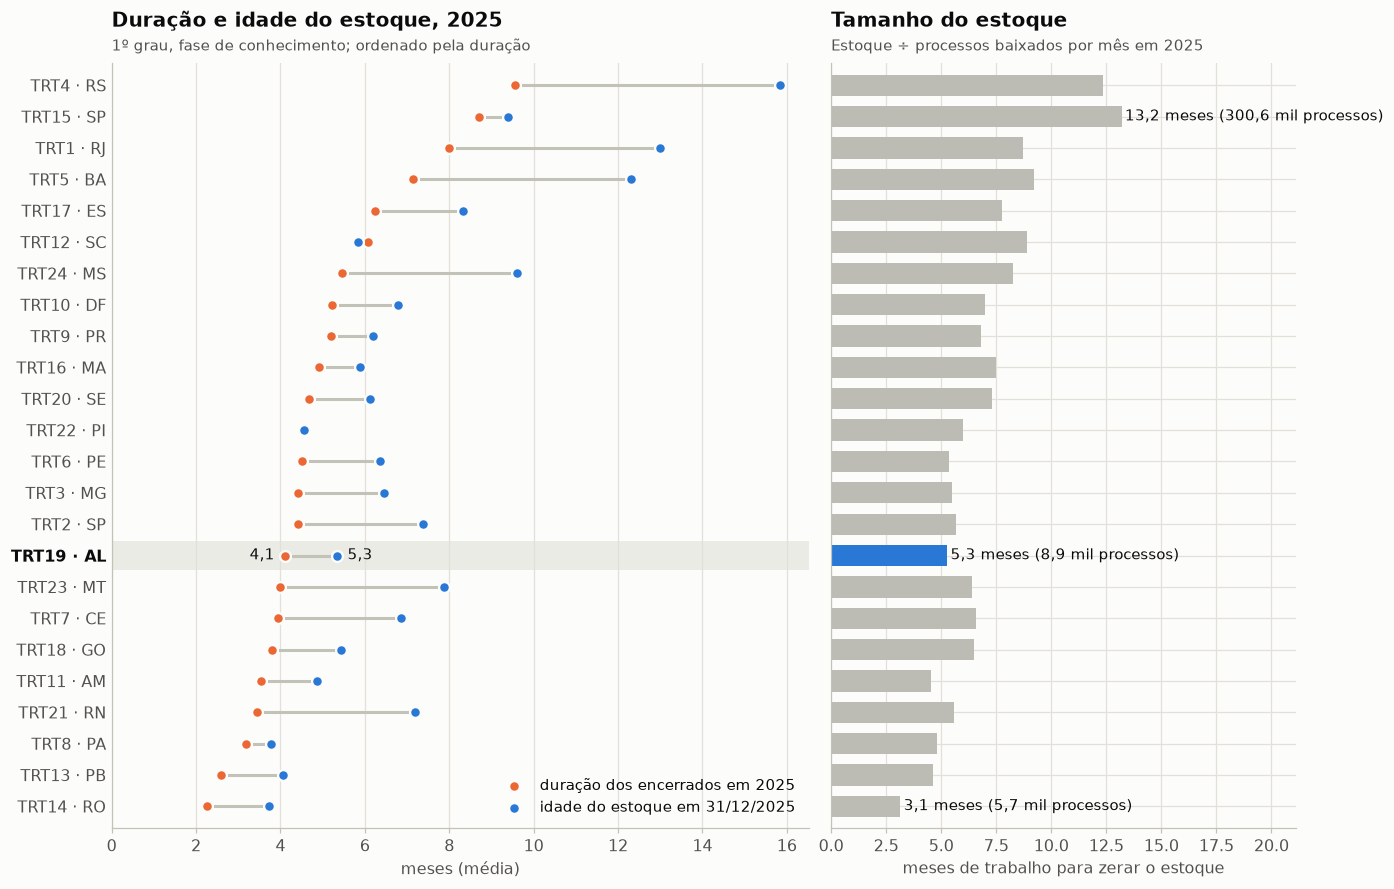

In [19]:
d = jt.sort_values("meses_ate_sentenca")
y = np.arange(len(d))
i_dest = list(d.index).index(DESTAQUE)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 8.2), sharey=True, gridspec_kw={"width_ratios": [1.5, 1]})
a1.axhspan(i_dest - 0.45, i_dest + 0.45, color=COR["grade"], alpha=0.6, lw=0, zorder=0)
a1.hlines(y, d["meses_ate_sentenca"], d["meses_idade_estoque"], color=COR["eixo"], lw=2, zorder=1)
a1.scatter(d["meses_ate_sentenca"], y, s=50, color=COR["laranja"], edgecolor=COR["fundo"], lw=1.5, zorder=3,
           label="duração dos encerrados em 2025")
a1.scatter(d["meses_idade_estoque"], y, s=50, color=COR["azul"], edgecolor=COR["fundo"], lw=1.5, zorder=3,
           label="idade do estoque em 31/12/2025")
for col, desloc, ha in [("meses_ate_sentenca", -7, "right"), ("meses_idade_estoque", 7, "left")]:
    a1.annotate(num(d.loc[DESTAQUE, col], 1), (d.loc[DESTAQUE, col], i_dest), xytext=(desloc, 0),
                textcoords="offset points", va="center", ha=ha, fontsize=9.5)
rotulos_trt(a1, list(d.index))
a1.set_xlim(0, None)
a1.set_xlabel("meses (média)")
a1.legend(loc="lower right", fontsize=9.5)
titulo(a1, f"Duração e idade do estoque, {ANO}", "1º grau, fase de conhecimento; ordenado pela duração")

cores = [COR["azul"] if s == DESTAQUE else COR["contexto"] for s in d.index]
a2.barh(y, d["meses_para_zerar_estoque"], color=cores, height=0.68)
for s in {DESTAQUE, d["meses_para_zerar_estoque"].idxmax(), d["meses_para_zerar_estoque"].idxmin()}:
    v = d.loc[s]
    a2.text(v["meses_para_zerar_estoque"] + 0.15, list(d.index).index(s),
            f"{num(v['meses_para_zerar_estoque'], 1)} meses ({num(v['pendentes'] / 1e3, 1)} mil processos)",
            va="center", fontsize=9.5)
a2.set_xlim(0, d["meses_para_zerar_estoque"].max() * 1.6)
a2.set_xlabel("meses de trabalho para zerar o estoque")
a2.tick_params(axis="y", length=0)
titulo(a2, "Tamanho do estoque", "Estoque ÷ processos baixados por mês em 2025")
fig.tight_layout()
salvar(fig, "fig1_duracao_e_estoque")
plt.show()

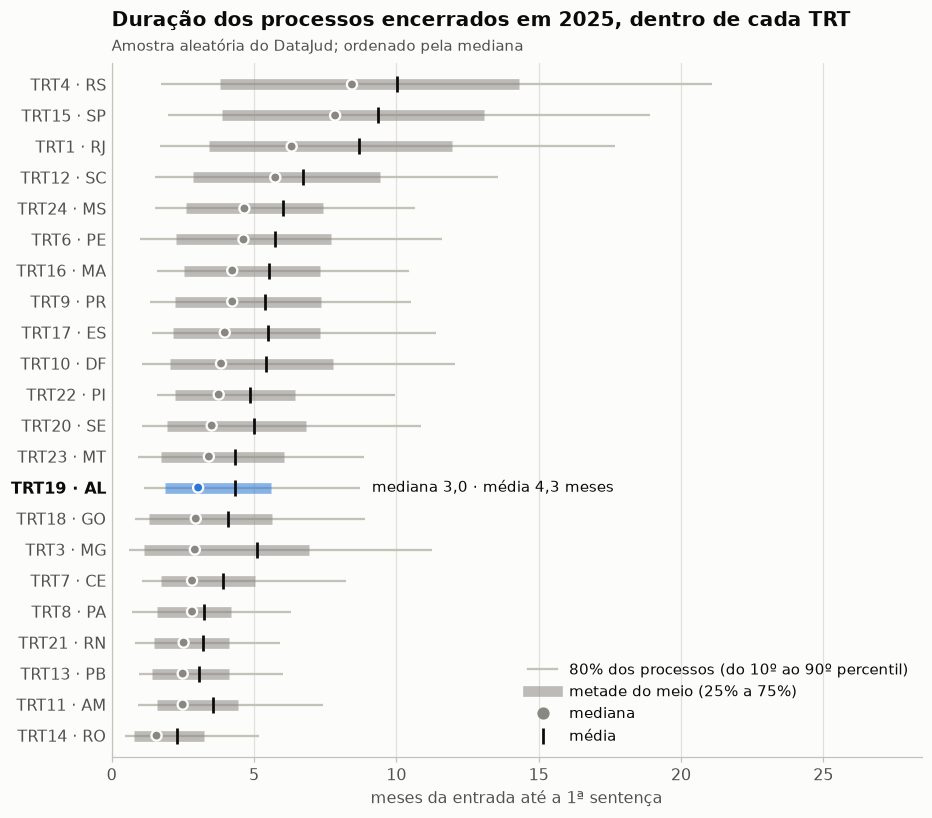

Todos os TRTs da amostra juntos (com pesos): metade dos processos termina em até 4,6 meses; 10% passam de 14,7 meses; média de 6,6 meses
A média é maior que a mediana em 22 de 22 TRTs
Entre TRTs: a maior mediana é 5,4 vezes a menor


In [20]:
q = dj.groupby("trt")["dias"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack() / MES
q.columns = ["p10", "p25", "mediana", "p75", "p90"]
q["média"] = dj.groupby("trt")["dias"].mean() / MES
q = q.sort_values("mediana")
y = np.arange(len(q))
cor = [COR["azul"] if s == DESTAQUE else COR["mudo"] for s in q.index]
fig, ax = plt.subplots(figsize=(9.5, 8.2))
ax.hlines(y, q["p10"], q["p90"], color=COR["eixo"], lw=1.5, zorder=1)
ax.hlines(y, q["p25"], q["p75"], color=cor, lw=7, alpha=0.55, zorder=2)
ax.scatter(q["mediana"], y, s=44, color=cor, edgecolor=COR["fundo"], lw=1.5, zorder=3)
ax.scatter(q["média"], y, marker="|", s=110, color=COR["tinta"], lw=1.8, zorder=4)
i = list(q.index).index(DESTAQUE)
ax.annotate(f"mediana {num(q['mediana'].iloc[i], 1)} · média {num(q['média'].iloc[i], 1)} meses",
            (q["p90"].iloc[i], i), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9.5)
rotulos_trt(ax, list(q.index))
ax.set_xlim(0, q["p90"].max() * 1.35)
ax.set_xlabel("meses da entrada até a 1ª sentença")
ax.legend(handles=[Line2D([], [], color=COR["eixo"], lw=1.5, label="80% dos processos (do 10º ao 90º percentil)"),
                   Line2D([], [], color=COR["mudo"], lw=7, alpha=0.55, label="metade do meio (25% a 75%)"),
                   Line2D([], [], marker="o", ls="", color=COR["mudo"], markersize=7, label="mediana"),
                   Line2D([], [], marker="|", ls="", color=COR["tinta"], markersize=11, mew=1.8, label="média")],
          loc="lower right", fontsize=9.5)
titulo(ax, f"Duração dos processos encerrados em {ANO}, dentro de cada TRT",
       "Amostra aleatória do DataJud; ordenado pela mediana")
salvar(fig, "fig2_variacao_dentro_do_trt")
plt.show()


def quantil_ponderado(v, pesos, q):
    ordem = np.argsort(v)
    acum = np.cumsum(pesos[ordem]) / pesos.sum()
    return v[ordem][np.searchsorted(acum, q)]


dias_v, pesos_v = dj["dias"].to_numpy(), dj["peso"].to_numpy()
print(f"Todos os TRTs da amostra juntos (com pesos): metade dos processos termina em até "
      f"{num(quantil_ponderado(dias_v, pesos_v, 0.5) / MES, 1)} meses; 10% passam de "
      f"{num(quantil_ponderado(dias_v, pesos_v, 0.9) / MES, 1)} meses; média de "
      f"{num(np.average(dias_v, weights=pesos_v) / MES, 1)} meses")
print(f"A média é maior que a mediana em {int((q['média'] > q['mediana']).sum())} de {len(q)} TRTs")
print(f"Entre TRTs: a maior mediana é {num(q['mediana'].max() / q['mediana'].min(), 1)} vezes a menor")

In [21]:
def resumo_ponderado(g):
    v, p = g["dias"].to_numpy() / MES, g["peso"].to_numpy()
    media = np.average(v, weights=p)
    return pd.Series({"processos": len(g), "% dos processos": 100 * p.sum() / dj["peso"].sum(),
                      "média": media, "desvio-padrão": np.sqrt(np.average((v - media) ** 2, weights=p)),
                      "10%": quantil_ponderado(v, p, 0.1), "mediana": quantil_ponderado(v, p, 0.5),
                      "90%": quantil_ponderado(v, p, 0.9)})


linhas_desc = {"Todos os processos": resumo_ponderado(dj)}
for coluna in ["rito", "encerramento"]:
    for valor, grupo in dj.groupby(coluna):
        linhas_desc[f"{coluna}: {valor}"] = resumo_ponderado(grupo)
descritiva = pd.DataFrame(linhas_desc).T
descritiva["processos"] = descritiva["processos"].astype(int)
display(descritiva.round(1))

,processos,% dos processos,média,desvio-padrão,10%,mediana,90%
Todos os processos,17175,100.0,6.6,6.4,1.1,4.6,14.7
rito: Ordinário,8927,54.9,8.1,7.0,1.6,6.3,16.7
rito: Sumaríssimo,8039,44.4,4.7,4.9,0.8,3.2,10.3
rito: Sumário (alçada),209,0.7,3.1,3.2,0.4,2.1,7.3
encerramento: acordo,5897,35.6,4.8,4.9,1.0,3.1,10.8
encerramento: extinção sem mérito,2389,11.7,2.3,2.8,0.1,1.6,5.4
encerramento: julgamento do mérito,8889,52.7,8.7,7.0,2.4,6.9,17.4


## 5. P2: a demora vem do tribunal ou do tipo de processo?
Um TRT pode ser lento por dois motivos:
- **perfil:** recebe processos mais complexos;
- **tribunal:** é mais lento mesmo com processos iguais.

Para separar os dois, comparamos processos de mesmo perfil entre TRTs.

| Decisão | Por quê |
|---|---|
| **Perfil** = rito, quantidade de assuntos e temas | é o que a API mostra de forma confiável na entrada do processo (o Juízo 100% Digital saiu, seção 3.1) |
| Tipo de encerramento fora do perfil | é um resultado, não uma característica de entrada. Ele entra na P3 |
| Variável resposta: log(dias) | a duração é muito assimétrica, e no log os efeitos viram variações percentuais |
| Vara como bloco separado | mostra se a demora é do TRT inteiro ou de algumas varas |
| A parte explicada em conjunto por tribunal e perfil é dividida igualmente entre os dois (valor de Shapley) | os dois blocos são correlacionados |
| Pesos por TRT | para o resultado valer para o conjunto dos TRTs |

Método: mínimos quadrados ponderados. A decomposição usa o R² ajustado dos modelos T, P, T+P e T+P+V (T = tribunal, P = perfil, V = vara).

In [22]:
def blocos_de(df):
    return {
        "T": pd.get_dummies(df["trt"], prefix="trt", drop_first=True),
        "P": pd.concat([pd.get_dummies(df["rito"], prefix="rito").drop(columns="rito_Ordinário", errors="ignore"),
                        pd.get_dummies(df["faixa_assuntos"], prefix="assuntos").drop(columns="assuntos_até 3"),
                        df[[f"tema: {t}" for t in TEMAS]]], axis=1),
        "E": pd.get_dummies(df["encerramento"], prefix="encerr").drop(columns="encerr_julgamento do mérito"),
        "V": pd.get_dummies(df["vara"], prefix="vara", drop_first=True),
    }


BLOCOS = {k: v.astype(float) for k, v in blocos_de(dj).items()}
y_log = np.log(dj["dias"].clip(lower=1)).to_numpy()
w = dj["peso"].to_numpy()


def regressao(blocos):
    X = pd.concat([pd.DataFrame({"constante": 1.0}, index=dj.index)] + [BLOCOS[b] for b in blocos], axis=1)
    sw = np.sqrt(w)
    beta, _, posto, _ = np.linalg.lstsq(X.to_numpy() * sw[:, None], y_log * sw, rcond=None)
    resid = y_log - X.to_numpy() @ beta
    r2 = 1 - np.sum(w * resid ** 2) / np.sum(w * (y_log - np.average(y_log, weights=w)) ** 2)
    r2_aj = 1 - (1 - r2) * (len(y_log) - 1) / (len(y_log) - posto)
    return r2_aj, pd.Series(beta, index=X.columns)


R = {nome: regressao(list(nome))[0] for nome in ["T", "P", "TP", "TPV"]}
decomp = 100 * pd.Series({
    "Tribunal (TRT)": (R["T"] + R["TP"] - R["P"]) / 2,
    "Perfil do processo": (R["P"] + R["TP"] - R["T"]) / 2,
    "Vara (dentro do TRT)": R["TPV"] - R["TP"],
    "Não explicado (caso a caso)": 1 - R["TPV"],
})
display(decomp.round(1).to_frame("% da variação da duração").T)

,Tribunal (TRT),Perfil do processo,Vara (dentro do TRT),Não explicado (caso a caso)
% da variação da duração,12.9,10.8,15.6,60.7


In [23]:
_, beta = regressao(["T", "P"])
perfil_medio = np.average(BLOCOS["P"].to_numpy() @ beta[BLOCOS["P"].columns].to_numpy(), weights=w)
efeito_trt = pd.Series(0.0, index=TRTS_AMOSTRA)
efeito_trt.update(beta[BLOCOS["T"].columns].rename(lambda c: c.replace("trt_", "")))
tipico = pd.DataFrame({
    "sem ajuste": np.exp(pd.Series(y_log, index=dj.index).groupby(dj["trt"]).mean()),
    "mesmo perfil": np.exp(beta["constante"] + efeito_trt + perfil_medio),
}).loc[TRTS_AMOSTRA] / MES
dispersao = np.log(tipico).std()
print(f"Diferença entre TRTs que continua depois do ajuste: {pct(100 * dispersao['mesmo perfil'] / dispersao['sem ajuste'], 0)}")
print(f"Mais lento ÷ mais rápido: sem ajuste {num(tipico['sem ajuste'].max() / tipico['sem ajuste'].min(), 1)} vezes; "
      f"com o mesmo perfil {num(tipico['mesmo perfil'].max() / tipico['mesmo perfil'].min(), 1)} vezes")

Diferença entre TRTs que continua depois do ajuste: 93%
Mais lento ÷ mais rápido: sem ajuste 4,7 vezes; com o mesmo perfil 4,0 vezes


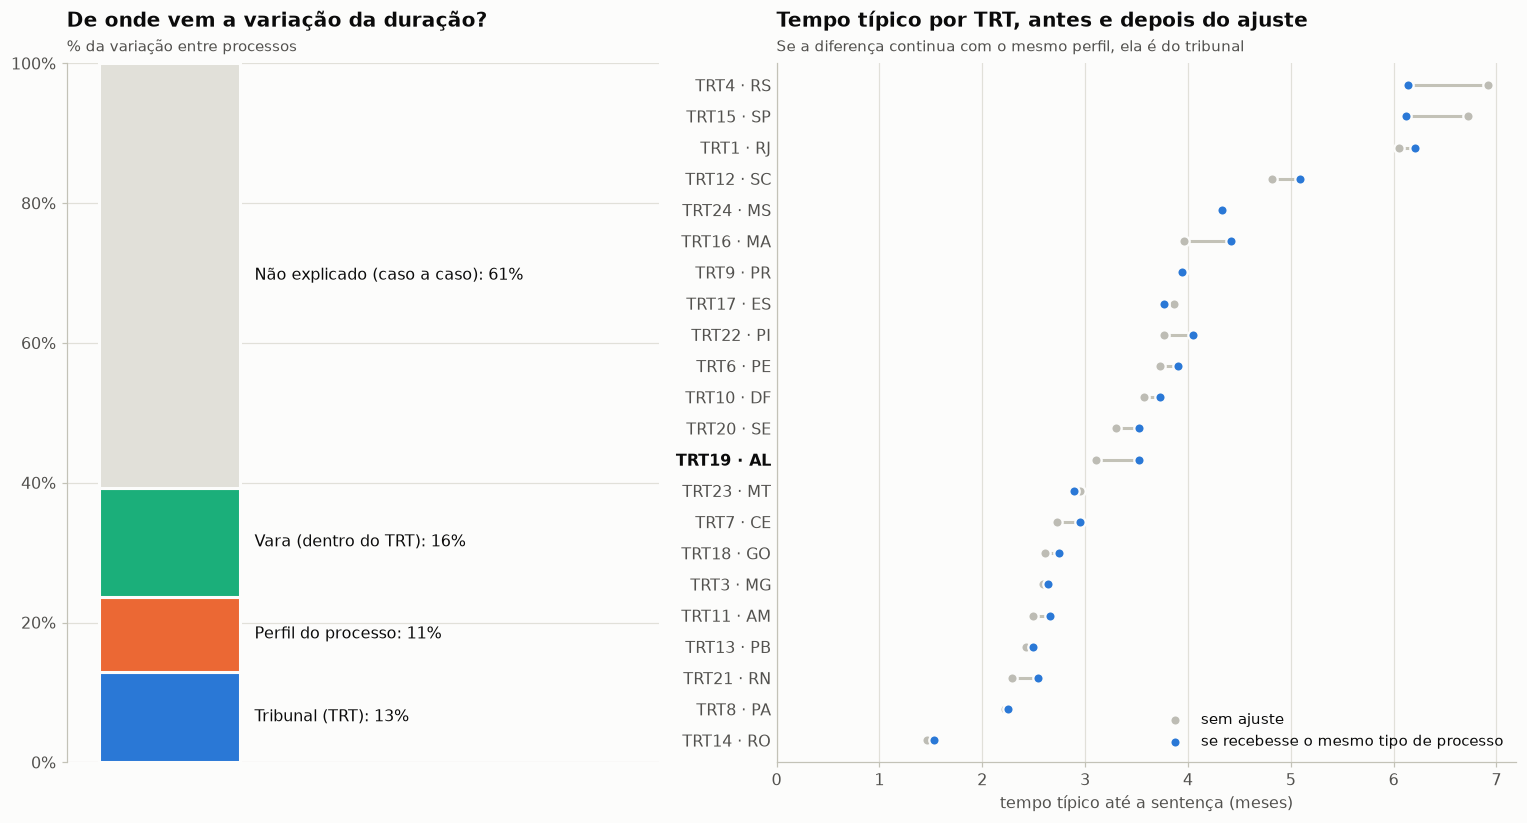

In [24]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 7.6), gridspec_kw={"width_ratios": [1, 1.25]})
base_barra = 0
for (rotulo, v), c in zip(decomp.items(), [COR["azul"], COR["laranja"], COR["verde"], COR["grade"]]):
    a1.bar(0, v, bottom=base_barra, color=c, width=0.55, edgecolor=COR["fundo"], lw=2)
    a1.text(0.33, base_barra + v / 2, f"{rotulo}: {pct(v, 0)}", va="center", fontsize=10.5)
    base_barra += v
a1.set_xlim(-0.4, 1.9)
a1.set_ylim(0, 100)
a1.set_xticks([])
a1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
a1.grid(axis="x", visible=False)
a1.spines["bottom"].set_visible(False)
titulo(a1, "De onde vem a variação da duração?", "% da variação entre processos")

t = tipico.sort_values("sem ajuste")
y = np.arange(len(t))
a2.hlines(y, t["sem ajuste"], t["mesmo perfil"], color=COR["eixo"], lw=2, zorder=1)
a2.scatter(t["sem ajuste"], y, s=46, color=COR["contexto"], edgecolor=COR["fundo"], lw=1.5, zorder=3, label="sem ajuste")
a2.scatter(t["mesmo perfil"], y, s=46, color=COR["azul"], edgecolor=COR["fundo"], lw=1.5, zorder=3,
           label="se recebesse o mesmo tipo de processo")
rotulos_trt(a2, list(t.index))
a2.set_xlim(0, None)
a2.set_xlabel("tempo típico até a sentença (meses)")
a2.legend(loc="lower right", fontsize=9.5)
titulo(a2, "Tempo típico por TRT, antes e depois do ajuste", "Se a diferença continua com o mesmo perfil, ela é do tribunal")
fig.tight_layout()
salvar(fig, "fig3_tribunal_ou_perfil")
plt.show()

## 6. P3: o que está associado à demora e ao acúmulo?
1. **Duração, processo a processo (amostra):** regressão de log(dias) com efeito fixo de TRT, perfil e tipo de encerramento. Efeito = exp(β) − 1, com IC 95% por bootstrap (300 reamostragens dentro de cada TRT).
2. **Acúmulo, tribunal a tribunal (dados oficiais):** correlação de Spearman entre os 24 TRTs. Com n = 24, só relações fortes são detectáveis.

A "carga de trabalho" do CNJ ficou de fora porque a fórmula dela já contém o estoque: a relação seria circular.

In [25]:
_, beta = regressao(["T", "P", "E"])
vars_efeito = list(BLOCOS["P"].columns) + list(BLOCOS["E"].columns)
rng = np.random.default_rng(2025)
grupos = [np.flatnonzero(dj["trt"].to_numpy() == s) for s in TRTS_AMOSTRA]
X_tpe = pd.concat([pd.DataFrame({"constante": 1.0}, index=dj.index)] + [BLOCOS[b] for b in "TPE"], axis=1).to_numpy()
boot = []
for _ in range(300):
    idx = np.concatenate([rng.choice(g, len(g), replace=True) for g in grupos])
    sw = np.sqrt(w[idx])
    b_, *_ = np.linalg.lstsq(X_tpe[idx] * sw[:, None], y_log[idx] * sw, rcond=None)
    boot.append(pd.Series(b_, index=beta.index)[vars_efeito])
boot = pd.DataFrame(boot)
efeitos = pd.DataFrame({
    "efeito (%)": 100 * (np.exp(beta[vars_efeito]) - 1),
    "margem: de": 100 * (np.exp(boot.quantile(0.025)) - 1),
    "margem: até": 100 * (np.exp(boot.quantile(0.975)) - 1),
    "% dos processos": 100 * np.average(pd.concat([BLOCOS["P"], BLOCOS["E"]], axis=1)[vars_efeito], axis=0, weights=w),
})
ROTULOS = {"rito_Sumaríssimo": "Rito sumaríssimo (vs. ordinário)", "rito_Sumário (alçada)": "Rito sumário (vs. ordinário)",
           "assuntos_4 a 6": "4 a 6 assuntos (vs. até 3)", "assuntos_7 a 10": "7 a 10 assuntos (vs. até 3)",
           "assuntos_11 ou mais": "11 ou mais assuntos (vs. até 3)",
           "encerr_acordo": "Encerrado por acordo (vs. julgamento)",
           "encerr_extinção sem mérito": "Extinto sem julgamento do mérito (vs. julgamento)"}
efeitos.index = [ROTULOS.get(c, c.replace("tema: ", "Tema: ")) for c in efeitos.index]
display(efeitos.round(1))

,efeito (%),margem: de,margem: até,% dos processos
Rito sumaríssimo (vs. ordinário),-31.4,-33.9,-29.0,44.4
Rito sumário (vs. ordinário),-39.9,-50.5,-28.1,0.7
4 a 6 assuntos (vs. até 3),4.6,-1.2,10.3,17.9
7 a 10 assuntos (vs. até 3),6.1,-2.7,14.1,12.0
11 ou mais assuntos (vs. até 3),7.7,-2.7,19.5,11.4
Tema: Rescisão do Contrato de Trabalho,-8.8,-12.5,-4.6,55.2
"Tema: Verbas Remuneratórias, Indenizatórias e Benefícios",12.0,7.7,17.3,43.5
Tema: Contrato Individual de Trabalho,-4.3,-8.5,0.3,32.8
Tema: Responsabilidade Civil do Empregador,9.6,4.9,14.6,29.5
Tema: Direito processual,-4.0,-8.7,1.0,25.5


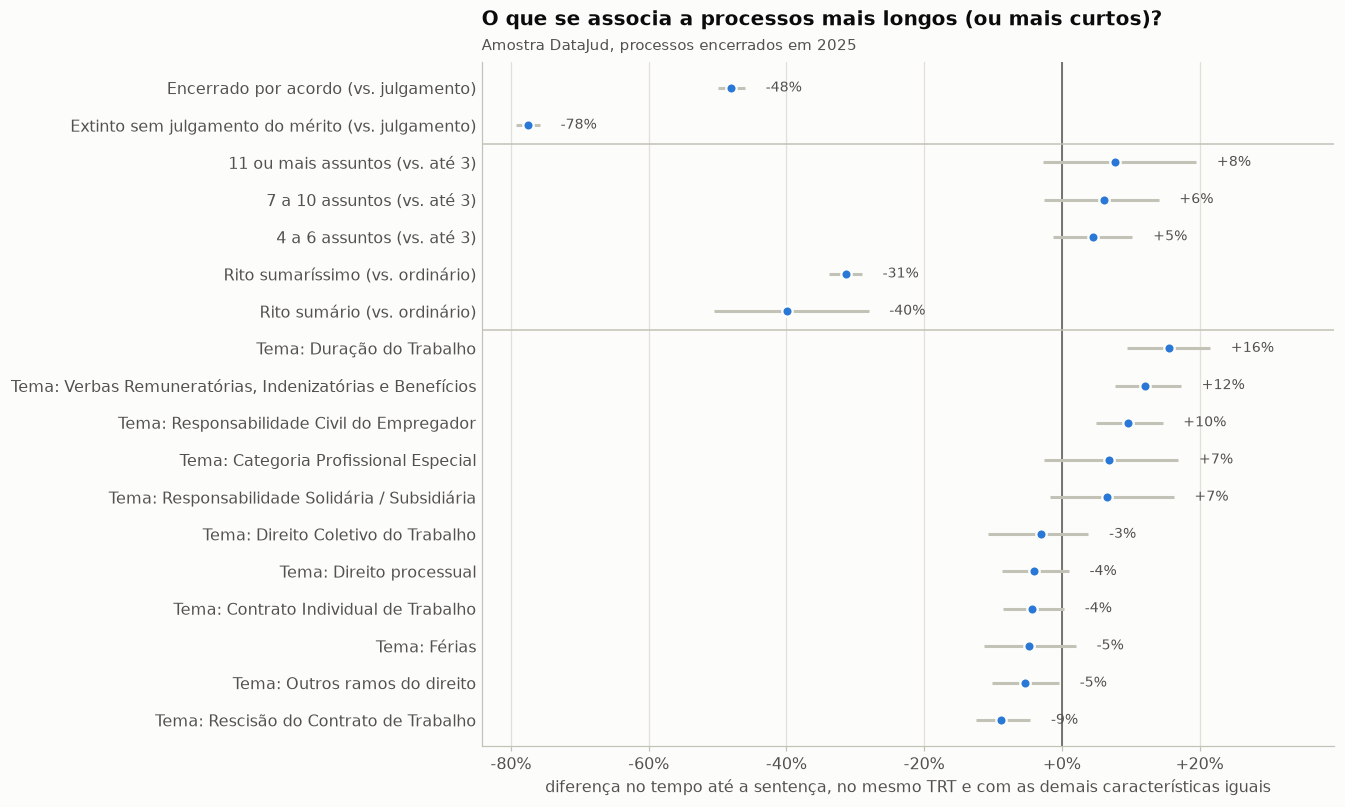

In [26]:
e = efeitos.copy()
e["grupo"] = np.select([e.index.str.startswith("Tema"), e.index.str.contains("vs. julgamento")], [2, 0], 1)
e = e.sort_values(["grupo", "efeito (%)"], ascending=[False, True])
y = np.arange(len(e))
fig, ax = plt.subplots(figsize=(10, 0.36 * len(e) + 1.6))
ax.axvline(0, color=COR["tinta2"], lw=1, zorder=1)
for i in np.flatnonzero(np.diff(e["grupo"].to_numpy())):
    ax.axhline(i + 0.5, color=COR["eixo"], lw=1, zorder=1)
ax.hlines(y, e["margem: de"], e["margem: até"], color=COR["eixo"], lw=2, zorder=2)
ax.scatter(e["efeito (%)"], y, s=46, color=COR["azul"], edgecolor=COR["fundo"], lw=1.5, zorder=3)
for i, (_, r) in enumerate(e.iterrows()):
    ax.text(max(r["margem: até"], r["efeito (%)"]) + 3, i, f"{r['efeito (%)']:+.0f}%", va="center", fontsize=9,
            color=COR["tinta2"])
ax.set_yticks(y, e.index)
ax.set_ylim(-0.7, len(e) - 0.3)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:+.0f}%"))
ax.set_xlim(min(-75, e["margem: de"].min() - 5), e["margem: até"].max() + 18)
ax.set_xlabel("diferença no tempo até a sentença, no mesmo TRT e com as demais características iguais")
titulo(ax, "O que se associa a processos mais longos (ou mais curtos)?", f"Amostra DataJud, processos encerrados em {ANO}")
salvar(fig, "fig4_fatores_da_duracao")
plt.show()

In [27]:
base_trt = jt.join(pd.DataFrame({
    "pct_sumarissimo": 100 * dj["rito"].eq("Sumaríssimo").groupby(dj["trt"]).mean(),
    "assuntos_mediana": dj.groupby("trt")["n_assuntos"].median(),
}))
FATORES = {"casos_novos_por_juiz": "casos novos por juiz (demanda)",
           "servidores_por_juiz": "servidores por juiz",
           "juizes": "tamanho do TRT (nº de juízes)",
           "indice_conciliacao": "% de acordos",
           "pct_suspensos": "% do estoque suspenso",
           "pct_sumarissimo": "% de rito sumaríssimo (amostra)",
           "assuntos_mediana": "assuntos por processo (amostra)"}
ALVOS = {"meses_ate_sentenca": "duração", "meses_idade_estoque": "idade do estoque",
         "meses_para_zerar_estoque": "estoque em meses de trabalho"}
tabela = {}
for f, rot_f in FATORES.items():
    tabela[rot_f] = {}
    for a, rot_a in ALVOS.items():
        par = base_trt[[f, a]].dropna()
        rho, p = stats.spearmanr(par[f], par[a])
        tabela[rot_f][rot_a] = num(rho, 2) + (" *" if p < 0.05 else "")
display(pd.DataFrame(tabela).T)
print(f"Correlação de Spearman entre os TRTs (24 nos fatores oficiais; {len(TRTS_AMOSTRA)} nos da amostra). "
      "* = p < 0,05")

,duração,idade do estoque,estoque em meses de trabalho
casos novos por juiz (demanda),"0,24","0,06","0,31"
servidores por juiz,"-0,19","-0,27","-0,15"
tamanho do TRT (nº de juízes),"0,34","0,43 *","0,27"
% de acordos,"0,05","0,10","0,08"
% do estoque suspenso,"0,10","0,11","0,15"
% de rito sumaríssimo (amostra),"-0,37","-0,32","-0,26"
assuntos por processo (amostra),"0,17","0,24","0,17"


Correlação de Spearman entre os TRTs (24 nos fatores oficiais; 22 nos da amostra). * = p < 0,05


## 7. Exercício: gráfico enganoso e versão corrigida
**Afirmação:** "os TRTs mais congestionados do país são o TRT15 e o TRT2".

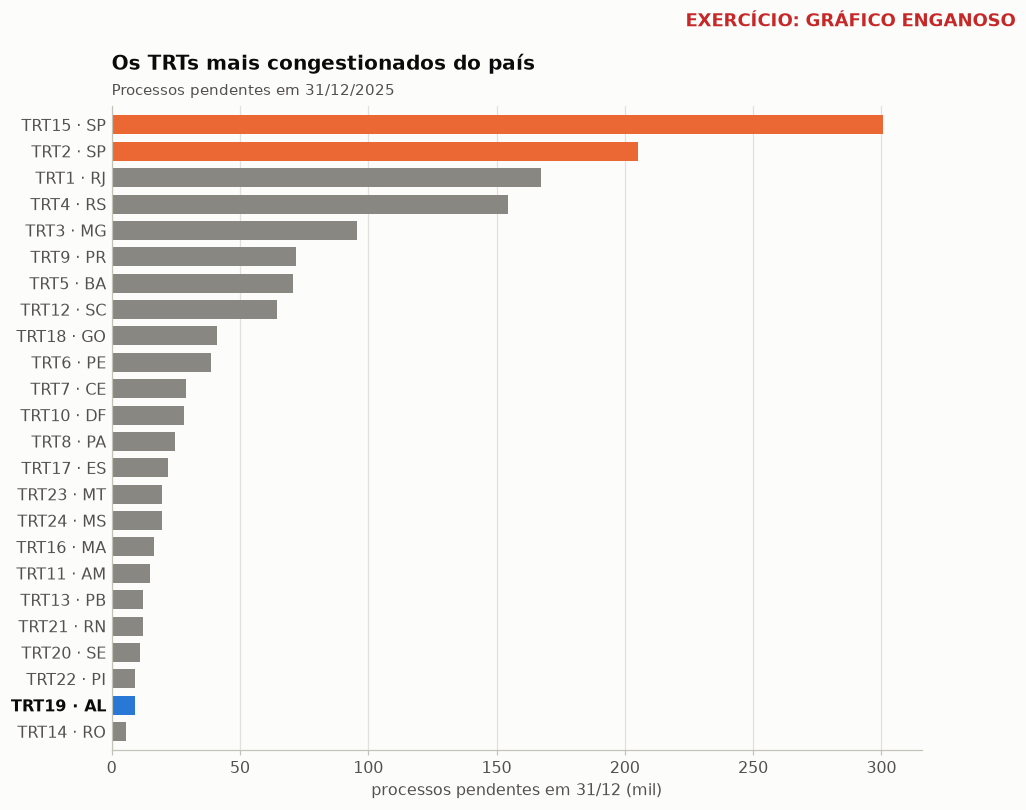

In [28]:
DOIS_MAIORES = list(jt["pendentes"].nlargest(2).index)
e5 = jt["pendentes"].sort_values()
fig, ax = plt.subplots(figsize=(9.5, 7.6))
cores = [COR["laranja"] if s in DOIS_MAIORES else COR["azul"] if s == DESTAQUE else COR["mudo"] for s in e5.index]
ax.barh(np.arange(len(e5)), e5 / 1000, color=cores, height=0.72)
rotulos_trt(ax, list(e5.index))
ax.set_xlabel("processos pendentes em 31/12 (mil)")
ax.grid(axis="y", visible=False)
titulo(ax, "Os TRTs mais congestionados do país", f"Processos pendentes em 31/12/{ANO}")
fig.text(0.99, 0.995, "EXERCÍCIO: GRÁFICO ENGANOSO", color=COR["vermelho"], fontsize=12, fontweight="bold",
         ha="right", va="top")
salvar(fig, "fig5_exercicio_grafico_enganoso")
plt.show()

**O erro:** o gráfico compara números absolutos entre tribunais de tamanhos muito diferentes. O TRT15 e o TRT2 têm os maiores estoques em boa parte porque estão entre os maiores tribunais. O título fala em congestionamento, mas o gráfico mostra tamanho.

**A correção:** usar uma medida relativa à capacidade de cada tribunal, a taxa de congestionamento do CNJ = pendentes ÷ (pendentes + baixados).

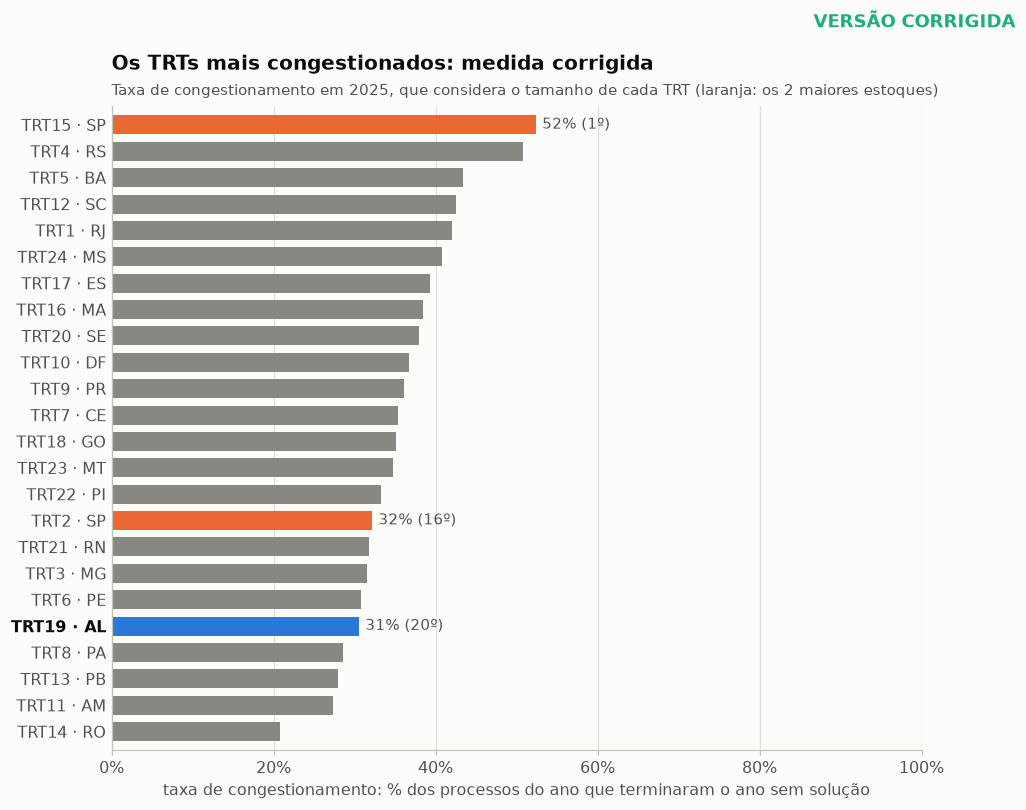

Posição no ranking (1º = mais congestionado):
       pelo estoque absoluto (enganoso)  pela taxa de congestionamento (correto)
sigla                                                                           
TRT15                                 1                                        1
TRT2                                  2                                       16
TRT19                                23                                       20


In [29]:
e6 = jt["tc"].sort_values()
posicao = e6.rank(ascending=False, method="min").astype(int)
fig, ax = plt.subplots(figsize=(9.5, 7.6))
cores = [COR["laranja"] if s in DOIS_MAIORES else COR["azul"] if s == DESTAQUE else COR["mudo"] for s in e6.index]
ax.barh(np.arange(len(e6)), e6, color=cores, height=0.72)
for i, s in enumerate(e6.index):
    if s in DOIS_MAIORES + [DESTAQUE]:
        ax.text(e6[s] + 0.8, i, f"{num(e6[s], 0)}% ({posicao[s]}º)", va="center", fontsize=9.5, color=COR["tinta2"])
rotulos_trt(ax, list(e6.index))
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xlabel("taxa de congestionamento: % dos processos do ano que terminaram o ano sem solução")
ax.grid(axis="y", visible=False)
titulo(ax, "Os TRTs mais congestionados: medida corrigida",
       f"Taxa de congestionamento em {ANO}, que considera o tamanho de cada TRT (laranja: os 2 maiores estoques)")
fig.text(0.99, 0.995, "VERSÃO CORRIGIDA", color=COR["verde"], fontsize=12, fontweight="bold", ha="right", va="top")
salvar(fig, "fig6_exercicio_versao_corrigida")
plt.show()
print("Posição no ranking (1º = mais congestionado):")
print(pd.DataFrame({"pelo estoque absoluto (enganoso)": jt["pendentes"].rank(ascending=False, method="min").astype(int),
                    "pela taxa de congestionamento (correto)": posicao}).loc[DOIS_MAIORES + [DESTAQUE]].to_string())

**O que muda com a medida correta:**
- **TRT15:** continua em 1º, com 52%. Aqui o gráfico enganoso acertou por acaso.
- **TRT2:** cai de 2º para 16º (32%). Tem o 2º maior estoque porque é o maior TRT (446 juízes).
- **TRT4 (RS) e TRT5 (BA):** o TRT4 sobe de 4º para 2º (51%), e o TRT5, de 7º para 3º (43%).
- **TRT19 · AL:** passa de 23º para 20º (31%).

**Lição:** para comparar grupos de tamanhos diferentes, é preciso normalizar (taxa, %, por juiz). O número absoluto mostra quem é maior, não quem está pior.

## 8. Ética e privacidade
- **Só dados públicos.** As duas fontes são abertas pelo próprio CNJ: a base do *Justiça em Números* e a API Pública do DataJud, acessada com a chave pública oficial.
- **Nenhum dado pessoal.** A API pública não traz nomes das partes, de advogados nem CPF. Pedimos só o necessário: datas, classe, assuntos, vara e códigos das movimentações. Todos os processos da amostra são públicos (nível de sigilo 0), e processos sigilosos não aparecem na API.
- **Número do processo vira código.** Com o número, qualquer pessoa pode abrir o processo no site do tribunal e ver os nomes. Por isso, na base tratada, ele foi trocado por um código sem volta (seção 3.1). O cache bruto guarda a resposta original da API, que não tem nomes, para que o trabalho possa ser conferido e repetido.
- **Uso responsável do servidor.** Pausas de 5 a 15 segundos quando a API está cheia, no máximo 2 pedidos ao mesmo tempo, identificação como projeto acadêmico e cache para nunca pedir o mesmo dado duas vezes.
- **Interpretação responsável.** Mostramos associações, não culpados. Não apontamos varas nem juízes, e comparamos tribunais com medidas relativas, para não penalizar os maiores (seção 7). Os tempos dependem do registro dos próprios tribunais.

## 9. Modelo de *machine learning* sugerido
**Objetivo:** prever, na entrada do processo, o tempo até a sentença a partir do TRT, da vara, do rito e dos assuntos, para sinalizar cedo os processos com risco de demora.
- **Modelo:** *Random Survival Forest*. Ele trata o problema como tempo até um evento e aproveita os processos ainda pendentes como observações censuradas, o que evita o viés de usar só os encerrados. Uma alternativa mais simples é *gradient boosting* (XGBoost ou LightGBM) no log da duração, só com os encerrados.
- **Validação:** separação entre treino e teste agrupada por vara. Comparação com a referência "tempo típico do TRT", usando o erro médio absoluto (em meses) e o índice C. Explicação dos resultados com SHAP.
- **Cuidado:** não usar variáveis posteriores à entrada, como o tipo de encerramento. Elas causariam vazamento de dados.

## 10. Relatório de resultados
**Bases:** dados oficiais do CNJ para os 24 TRTs. Amostra do DataJud com 17.175 processos de 22 TRTs (sem o TRT2 e o TRT5).

### P1. Como se distribuem a duração e o estoque pendente nos 24 TRTs?
**Resposta:** de forma muito desigual, e a duração e o estoque andam juntos.
- **Duração média até a 1ª sentença** (oficial, Figura 1): de 2,3 meses (TRT14 · RO/AC) a 9,6 meses (TRT4 · RS), uma diferença de 4,2 vezes. A mediana dos TRTs é de 4,5 meses.
- **Estoque em 31/12/2025:** 1,44 milhão de processos, de 5,7 mil (TRT14) a 300,6 mil (TRT15). Em meses de trabalho, vai de 3,1 a 13,2. O Spearman entre a duração e o estoque em meses de trabalho é de 0,91.
- **Duração × idade do estoque:** em 23 dos 24 TRTs, a idade média do estoque supera a duração dos encerrados. Medir só os encerrados subestima a demora.
- **Dentro dos TRTs** (amostra, Figura 2): a distribuição é assimétrica.
  - Mediana de 4,6 meses, média de 6,6 e desvio-padrão de 6,4. Em 10% dos processos, a duração passa de 14,7 meses.
  - A média supera a mediana em todos os 22 TRTs.
  - No TRT4, os 10% mais rápidos terminam em até 1,7 mês, e os 10% mais lentos levam mais de 21 meses.
- **Por rito e por encerramento** (medianas):
  - ordinário: 6,3 meses; sumaríssimo: 3,2 meses;
  - julgamento do mérito: 6,9 meses; acordo: 3,1 meses.

### P2. Quanto da variação na duração se deve ao tribunal e quanto ao perfil dos processos?
**Resposta:** a diferença entre os TRTs vem do tribunal, não do perfil dos processos.
- **TRTs com o mesmo perfil** (Figura 3, direita): 93% da dispersão entre os TRTs permanece. A razão entre o mais lento e o mais rápido passa de 4,7 para 4,0.
- **Variação entre processos** (Figura 3, esquerda): 61% é caso a caso, 16% é da vara, 13% do tribunal e 11% do perfil. A vara pesa tanto quanto o TRT.
- **TRT4 e TRT15:** recebem processos um pouco mais pesados (30% a 40% de sumaríssimo, contra cerca de 50% nos demais). Com o ajuste, o tempo típico cai de 6,9 e 6,7 meses para 6,1, e os dois continuam entre os mais lentos.
- **Ressalva:** só parte do perfil é observável (falta o valor da causa e o tipo de empresa). Por isso, a parcela do tribunal é um teto.

### P3. Quais fatores estão mais associados à longa duração e ao acúmulo?
**Resposta:** no processo, pesam o tipo de encerramento, o rito e o tema. Entre os tribunais, nenhum indicador oficial de estrutura explica a diferença.
- **Processo** (mesmo TRT, Figura 4):
  - encerramento, contra o julgamento: acordo −48%; extinção sem mérito −78%;
  - rito, contra o ordinário: sumaríssimo −31%;
  - temas: duração do trabalho +16%; verbas remuneratórias +12%; responsabilidade civil do empregador +10%; rescisão −9%;
  - quantidade de assuntos: +5% a +8%, com IC 95% que inclui zero.
- **Tribunal** (Spearman, 24 TRTs):
  - nenhuma relação significativa: casos novos por juiz 0,24; servidores por juiz −0,19; % de acordos 0,05; % do estoque suspenso 0,10;
  - a única significativa: tamanho do TRT × idade do estoque, 0,43 (p < 0,05).
- **Hipótese a investigar:** como a diferença é do tribunal e da vara (P2), mas não aparece nos indicadores de estrutura, ela deve estar ligada à gestão, como a pauta de audiências e a organização das varas.

### TRT19 · AL
- **Duração e estoque:** 4,1 meses até a sentença (9º mais rápido) e estoque jovem (5,3 meses), depois da redução do estoque em 2023.
- **Congestionamento:** taxa de 31%, o 20º maior entre os 24 TRTs.
- **Perfil:** recebe processos um pouco mais simples (60% de sumaríssimo). Com o mesmo perfil dos outros, iria de 3,1 para 3,5 meses e continuaria em 10º de 22.

### Principais achados
1. A desigualdade entre os TRTs é grande, e a duração e o estoque andam juntos.
2. Medir só os encerrados engana: em 23 de 24 TRTs, o estoque é mais velho que a duração.
3. A diferença entre os TRTs é do tribunal, e a vara pesa tanto quanto o TRT.
4. O acordo e o rito sumaríssimo encurtam o processo; temas que exigem mais prova o alongam.
5. Os indicadores oficiais de estrutura não explicam quais TRTs são lentos.
6. O efeito de −41% do Juízo 100% Digital era um artefato do ano de entrada e foi descartado (seção 3.1).
7. Comparar estoques absolutos engana: o TRT2 vai de 2º para 16º quando se usa a taxa de congestionamento (seção 7).

### Limitações
- **Associação, não causa.**
- **Perfil observado limitado:** sem o valor da causa e o tipo de empresa.
- **Amostra:** de 513 a 1.127 processos por TRT, só os públicos, e sem o TRT2 e o TRT5. Os resultados dela valem para os outros 22 TRTs.
- **Registro:** a "1ª sentença" depende de como os tribunais registram as movimentações.
- **Só os encerrados têm duração exata.** O estoque entra apenas pela idade média oficial.
- **n = 24 na comparação entre tribunais:** só relações fortes são detectáveis.

## Referências

- CNJ. *Justiça em Números 2026* (ano-base 2025), relatório e base de dados. https://www.cnj.jus.br/pesquisas-judiciarias/justica-em-numeros/
- CNJ. API Pública do DataJud: documentação e chave de acesso. https://datajud-wiki.cnj.jus.br/api-publica/
- CNJ. Tabelas Processuais Unificadas (TPU): classes, assuntos e movimentos. https://www.cnj.jus.br/sgt/consulta_publica_classes.php
- TST. Estatísticas da Justiça do Trabalho. https://www.tst.jus.br/web/estatistica/estatisticas